# Kredi Temerrüt Tahmini için 1D-CNN (PyTorch)
### Uçtan Uca Yapay Zekâ Projesi: Veriden Tahmine — Derin Öğrenme Bölümü

**Hazırlayan:** Umut Barbaros BABAHAN (230212065) — OSTİM Teknik Üniversitesi, Yapay Zekâ Mühendisliği

**Veri seti:** Türkiye 2026 Kredi Temerrüt Dataset — Kaggle
<https://www.kaggle.com/datasets/kivancbaysal/trkiye-2026-kredi-temerrt-dataset>

Bu notebook, banka müşterilerinin kredi temerrüdüne düşüp düşmeyeceğini tahmin eden bir **tablo verisi için 1 boyutlu evrişimli sinir ağı (1D-CNN)** geliştirir. Akış, proje şablonundaki adımları sırasıyla izler:

1. Problem tanımı
2. Veri setinin tanıtılması
3. Veri keşfi (EDA)
4. Veri ön işleme
5. Model tasarımı (Feature Tokenizer + 1D-CNN)
6. Model eğitimi
7. Model değerlendirme
8. Hata analizi
9. Sonuç ve geliştirme önerileri
10. Modelin dışa aktarılması (deneme uygulaması için)

## 1. Problem Tanımı

**Girdi:** Bir müşterinin demografik bilgileri (yaş, eğitim, şehir), çalışma ve gelir durumu, bankayla ilişkisi, kredi skoru, kredi kartı ve kredi kullanımı, toplam borç yükü ve son 12 aydaki ödeme davranışı.

**Çıktı:** Müşterinin temerrüde düşme olasılığı (0–1). Bu olasılık bir eşikle karşılaştırılarak ikili karar (`0 = ödüyor`, `1 = temerrüt`) üretilir.

**Gerçek dünya ihtiyacı:** Bankalar için temerrüt, doğrudan sermaye kaybı demektir. Riskli müşteriyi kredi verilmeden önce fark etmek kayıpları azaltır. Öte yandan iyi müşteriyi gereksiz yere reddetmek de gelir kaybıdır. Bu nedenle problem, iki hata türünün dengelenmesini gerektiren **dengesiz bir ikili sınıflandırma** problemidir.

In [1]:
# ============================================================
# Kütüphaneler ve genel ayarlar
# ============================================================
import os, json, time, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")

# Dosya yolları — CSV dosyası notebook ile aynı klasörde olmalı
DATA_PATH = "turkiye_2026_temerrut_tahmin_verisi_100k.csv"
FIG_DIR   = "figures"        # rapor için grafikler buraya kaydedilir
OUT_DIR   = "model_export"   # eğitilmiş model ve uygulama dosyaları
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# Tekrarlanabilirlik: tüm rastgelelik kaynaklarını aynı tohumla sabitliyoruz
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Cihaz:", DEVICE)

# Grafik stili: sade eksenler, açık ızgara, iki sınıf için sabit renkler
RENK_ODEDI, RENK_TEMERRUT = "#2a78d6", "#eb6834"   # 0 = ödedi (mavi), 1 = temerrüt (turuncu)
RENK_NEG, RENK_POZ, RENK_GRI = "#2a78d6", "#e34948", "#c3c2b7"
# Boyutlar IEEE raporuna göre: tek sütun = 3,5 in, tam sayfa = 7,16 in -> yazılar baskıda ~7 pt
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "font.size": 7.5, "pdf.fonttype": 42,
    "axes.labelsize": 7.5, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.8,
    "lines.linewidth": 1.5, "lines.markersize": 4,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})

def kaydet(fig, ad):
    """Grafiği PNG (README/notebook) ve PDF (LaTeX raporu, vektörel) olarak kaydeder."""
    fig.savefig(f"{FIG_DIR}/{ad}.png", bbox_inches="tight")
    fig.savefig(f"{FIG_DIR}/{ad}.pdf", bbox_inches="tight")
    plt.show()

# Grafiklerde ve uygulamada kullanılacak Türkçe etiketler
ETIKET = {
    "Yas": "Yaş", "Egitim_Durumu": "Eğitim durumu", "Sehir": "Şehir", "Calisma_Durumu": "Çalışma durumu",
    "Sektor": "Sektör", "Aylik_Gelir_TL": "Aylık gelir", "Calisma_Suresi_Yil": "Çalışma süresi",
    "Banka_Musterilik_Suresi_Ay": "Bankada müşterilik süresi", "Aktif_Urun_Sayisi": "Aktif ürün sayısı",
    "Dijital_Bankacilik_Kullanim_Skoru": "Dijital bankacılık skoru", "Kredi_Gecmisi_Yil": "Kredi geçmişi",
    "Kredi_Skoru": "Kredi skoru", "Kredi_Karti_Limiti_TL": "Kart limiti",
    "Kredi_Karti_Kullanim_Orani": "Kart kullanım oranı", "Kredi_Karti_Borcu_TL": "Kart borcu",
    "Kredi_Tutari_TL": "Kredi tutarı", "Kredi_Vadesi_Ay": "Kredi vadesi",
    "Aylik_Kredi_Odemesi_TL": "Aylık kredi ödemesi", "Toplam_Borc_TL": "Toplam borç",
    "Borc_Gelir_Orani": "Borç / yıllık gelir", "Aylik_Borc_Odeme_Orani": "Aylık ödeme / gelir",
    "Son_12_Ay_Odeme_Orani": "Son 12 ay ödeme oranı", "Gec_Odeme_Sayisi_12_Ay": "Geç ödeme sayısı (12 ay)",
    "Maksimum_Gecikme_Gunu": "Maksimum gecikme günü",
}

PyTorch: 2.14.1+cu130 | Cihaz: cpu


## 2. Veri Setinin Tanıtılması

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Satır (müşteri) sayısı : {df.shape[0]:,}")
print(f"Sütun (değişken) sayısı: {df.shape[1]}")
df.head()

Satır (müşteri) sayısı : 100,000
Sütun (değişken) sayısı: 28


,Musteri_ID,Musteri_Adi,Yas,Cinsiyet,Sehir,Egitim_Durumu,Calisma_Durumu,Sektor,Aylik_Gelir_TL,Calisma_Suresi_Yil,...,Toplam_Borc_TL,Borc_Gelir_Orani,Gec_Odeme_Sayisi_12_Ay,Maksimum_Gecikme_Gunu,Son_12_Ay_Odeme_Orani,Aylik_Borc_Odeme_Orani,Banka_Musterilik_Suresi_Ay,Aktif_Urun_Sayisi,Dijital_Bankacilik_Kullanim_Skoru,Temerrut
0,TR20260000001,Derya,30,E,Kocaeli,Lisans,Maaşlı,Ticaret,59900,8,...,28533,0.040,1,1,1.209,0.016,132,4,43,0
1,TR20260000002,Cem,42,E,Kayseri,Lisans,Maaşlı,Finans,84200,12,...,198748,0.197,4,30,0.542,0.085,146,3,80,0
2,TR20260000003,Fatma,18,E,Malatya,Önlisans,Maaşlı,Ticaret,30800,0,...,364056,0.985,1,7,1.106,0.268,37,4,85,0
3,TR20260000004,Barış,54,K,Erzurum,Lise,Maaşlı,Ticaret,70200,21,...,255107,0.303,2,15,0.839,0.154,218,3,26,0
4,TR20260000005,Mert,46,K,İstanbul,Lisans,Maaşlı,Özel_Sektör,74200,20,...,647844,0.728,1,30,1.117,0.299,151,3,82,0


In [3]:
# Değişken tipleri ve eksik değer kontrolü
bilgi = pd.DataFrame({
    "tip": df.dtypes.astype(str),
    "eksik_deger": df.isna().sum(),
    "benzersiz_deger": df.nunique(),
})
bilgi

,tip,eksik_deger,benzersiz_deger
Musteri_ID,str,0,100000
Musteri_Adi,str,0,30
Yas,int64,0,58
Cinsiyet,str,0,2
Sehir,str,0,30
Egitim_Durumu,str,0,5
Calisma_Durumu,str,0,5
Sektor,str,0,10
Aylik_Gelir_TL,int64,0,1475
Calisma_Suresi_Yil,int64,0,41


In [4]:
# Hedef değişkenin dağılımı -> sınıf dengesizliği
hedef_sayim = df["Temerrut"].value_counts().sort_index()
hedef_oran  = df["Temerrut"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"adet": hedef_sayim, "oran_%": (hedef_oran * 100).round(2)}))
print(f"\nDengesizlik oranı (0/1): {hedef_sayim[0] / hedef_sayim[1]:.2f} : 1")

           adet  oran_%
Temerrut               
0         87102    87.1
1         12898    12.9

Dengesizlik oranı (0/1): 6.75 : 1


**Veri setinin yapısı**

| Grup | Değişkenler |
|---|---|
| Kimlik (modelde kullanılmaz) | `Musteri_ID`, `Musteri_Adi` |
| Demografi | `Yas`, `Cinsiyet`, `Sehir` (30 il), `Egitim_Durumu` (5 seviye) |
| İş ve gelir | `Calisma_Durumu` (5), `Sektor` (10), `Aylik_Gelir_TL`, `Calisma_Suresi_Yil` |
| Banka ilişkisi | `Banka_Musterilik_Suresi_Ay`, `Aktif_Urun_Sayisi`, `Dijital_Bankacilik_Kullanim_Skoru` |
| Kredi geçmişi | `Kredi_Gecmisi_Yil`, `Kredi_Skoru` (350–850) |
| Kredi kartı | `Kredi_Karti_Limiti_TL`, `Kredi_Karti_Kullanim_Orani` (%), `Kredi_Karti_Borcu_TL` |
| Kredi | `Kredi_Tutari_TL`, `Kredi_Vadesi_Ay`, `Aylik_Kredi_Odemesi_TL` |
| Borç yükü | `Toplam_Borc_TL`, `Borc_Gelir_Orani`, `Aylik_Borc_Odeme_Orani` |
| Ödeme davranışı | `Son_12_Ay_Odeme_Orani`, `Gec_Odeme_Sayisi_12_Ay`, `Maksimum_Gecikme_Gunu` |
| **Hedef** | `Temerrut` (0 = ödüyor, 1 = temerrüt) |

- 100.000 müşteri ve 28 sütun var; **hiç eksik değer yok**.
- Hedef dengesiz: müşterilerin yaklaşık **%87,1**'i ödüyor, **%12,9**'u temerrüde düşüyor. Bu yüzden *accuracy* tek başına yanıltıcıdır. Her müşteriye "ödüyor" diyen bir model bile %87 doğruluk alır.

## 3. Veri Keşfi (EDA)

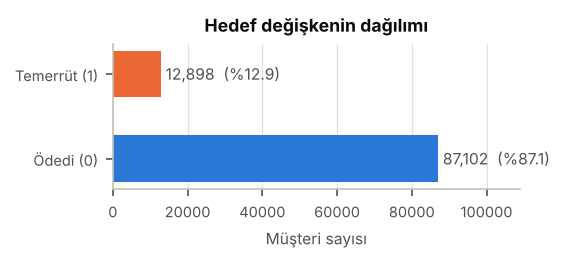

In [5]:
# Grafik 1 — Hedef sınıf dağılımı
fig, ax = plt.subplots(figsize=(3.5, 1.25))
etiketler = ["Ödedi (0)", "Temerrüt (1)"]
ax.barh(etiketler, hedef_sayim.values, color=[RENK_ODEDI, RENK_TEMERRUT], height=0.55)
for i, (n, o) in enumerate(zip(hedef_sayim.values, hedef_oran.values)):
    ax.text(n + 1200, i, f"{n:,}  (%{o*100:.1f})", va="center", color="#52514e")
ax.set_xlim(0, hedef_sayim.max() * 1.25)
ax.set_xlabel("Müşteri sayısı"); ax.grid(axis="y", visible=False)
ax.set_title("Hedef değişkenin dağılımı")
kaydet(fig, "fig01_hedef_dagilimi")

**Gözlem:** Her 8 müşteriden yaklaşık 1'i temerrüde düşüyor. Model eğitilirken azınlık sınıfı ağırlıklandırılmalı (`pos_weight`) ve karar eşiği 0,5'te bırakılmayıp ayarlanmalı. Değerlendirmede accuracy yerine precision, recall, F1 ve PR-AUC esas alınmalı.

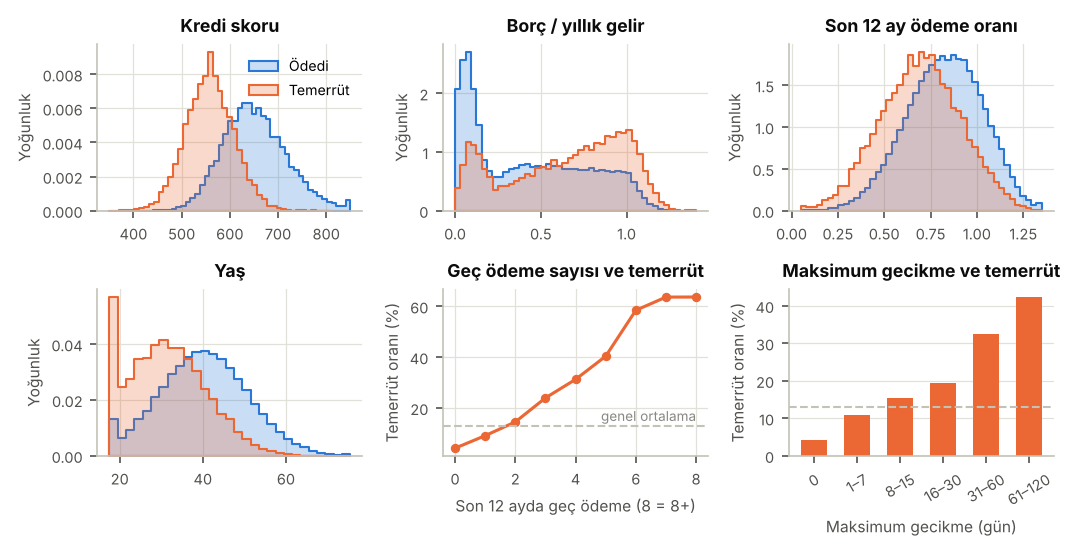

In [6]:
# Grafik 2 — Önemli sayısal değişkenlerin sınıflara göre dağılımı
fig, axes = plt.subplots(2, 3, figsize=(7.16, 3.7))
yogunluk_degiskenleri = [("Kredi_Skoru", "Kredi skoru"), ("Borc_Gelir_Orani", "Borç / yıllık gelir"),
                         ("Son_12_Ay_Odeme_Orani", "Son 12 ay ödeme oranı"), ("Yas", "Yaş")]
for ax, (col, ad) in zip(axes.flat[:4], yogunluk_degiskenleri):
    for sinif, renk, etiket in [(0, RENK_ODEDI, "Ödedi"), (1, RENK_TEMERRUT, "Temerrüt")]:
        bins = np.arange(17.5, 76.5, 2) if col == "Yas" else 45   # yaş tam sayı: 2'şer yıllık kutular
        sns.histplot(df.loc[df.Temerrut == sinif, col], ax=ax, stat="density", bins=bins,
                     element="step", fill=True, alpha=0.25, color=renk, linewidth=1.0, label=etiket)
    ax.set_title(ad); ax.set_xlabel(""); ax.set_ylabel("Yoğunluk")
axes.flat[0].legend()

# Kesikli değişkenlerde yoğunluk yerine "temerrüt oranı" daha okunaklı
genel_oran = df.Temerrut.mean()
oran = df.groupby(df.Gec_Odeme_Sayisi_12_Ay.clip(upper=8)).Temerrut.mean()
ax = axes.flat[4]
ax.plot(oran.index, oran.values * 100, marker="o", color=RENK_TEMERRUT, lw=1.5, ms=3.5)
ax.axhline(genel_oran * 100, color=RENK_GRI, ls="--", lw=1)
ax.text(8, genel_oran * 100 + 2, "genel ortalama", ha="right", color="#898781", fontsize=6.5)
ax.set_title("Geç ödeme sayısı ve temerrüt"); ax.set_xlabel("Son 12 ayda geç ödeme (8 = 8+)")
ax.set_ylabel("Temerrüt oranı (%)")

gecikme_bin = pd.cut(df.Maksimum_Gecikme_Gunu, [-1, 0, 7, 15, 30, 60, 120],
                     labels=["0", "1–7", "8–15", "16–30", "31–60", "61–120"])
oran = df.groupby(gecikme_bin, observed=True).Temerrut.mean()
ax = axes.flat[5]
ax.bar(oran.index.astype(str), oran.values * 100, color=RENK_TEMERRUT, width=0.6)
ax.axhline(genel_oran * 100, color=RENK_GRI, ls="--", lw=1)
ax.set_title("Maksimum gecikme ve temerrüt"); ax.set_xlabel("Maksimum gecikme (gün)")
ax.set_ylabel("Temerrüt oranı (%)"); ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
kaydet(fig, "fig02_sayisal_dagilimlar")

**Gözlemler:**
- **Kredi skoru** en ayırt edici değişken. Temerrüde düşenlerin dağılımı belirgin şekilde sola (düşük skora) kaymış.
- **Borç/gelir oranı** yükseldikçe temerrüt yoğunluğu artıyor. **Son 12 ay ödeme oranı** düştükçe risk artıyor.
- Temerrüde düşenler ortalamada **daha genç**.
- **Geç ödeme sayısı** ve **maksimum gecikme** ile temerrüt oranı arasında güçlü, tekdüze artan bir ilişki var. Geçmiş ödeme davranışı geleceği iyi öngörüyor.
- Dağılımlar iki sınıf arasında büyük ölçüde **örtüşüyor**. Hiçbir tek değişken sınıfları tek başına ayıramıyor; modelin değişkenleri birlikte kullanması gerekiyor.

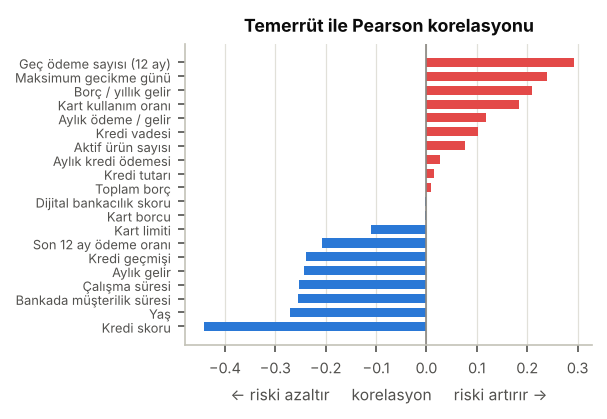

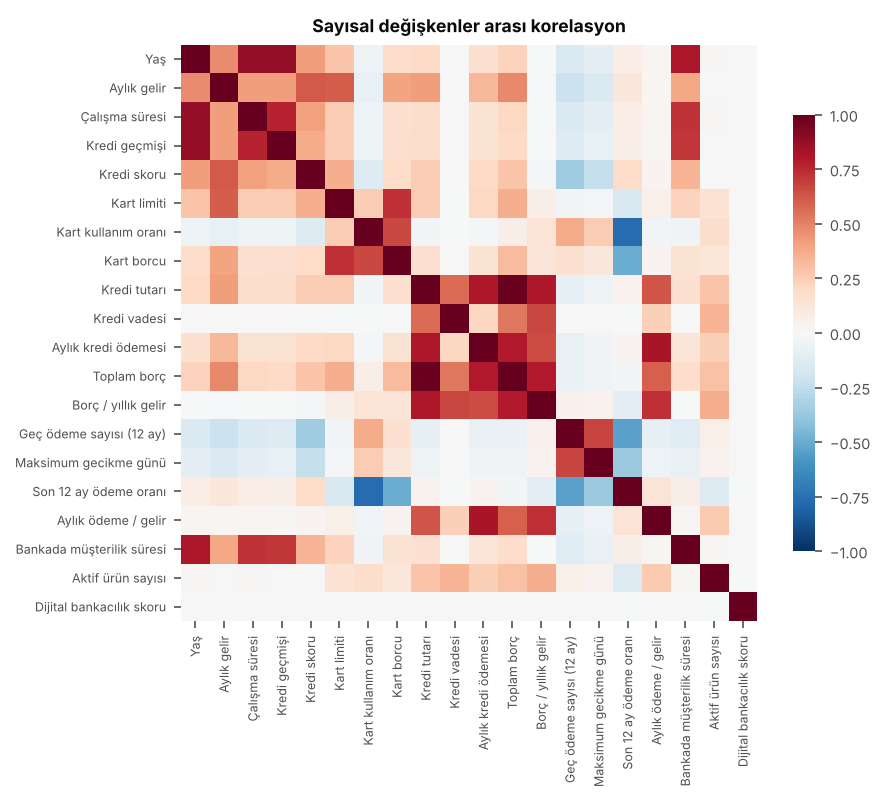

Yüksek korelasyonlu çiftler (|r| > 0.7):
Kredi_Tutari_TL             Toplam_Borc_TL                0.985
Yas                         Calisma_Suresi_Yil            0.882
                            Kredi_Gecmisi_Yil             0.876
Aylik_Kredi_Odemesi_TL      Aylik_Borc_Odeme_Orani        0.824
Yas                         Banka_Musterilik_Suresi_Ay    0.819
Kredi_Tutari_TL             Aylik_Kredi_Odemesi_TL        0.809
                            Borc_Gelir_Orani              0.809
Aylik_Kredi_Odemesi_TL      Toplam_Borc_TL                0.797
Toplam_Borc_TL              Borc_Gelir_Orani              0.792
Calisma_Suresi_Yil          Kredi_Gecmisi_Yil             0.772
Kredi_Karti_Limiti_TL       Kredi_Karti_Borcu_TL          0.734
Borc_Gelir_Orani            Aylik_Borc_Odeme_Orani        0.731
Calisma_Suresi_Yil          Banka_Musterilik_Suresi_Ay    0.722
Kredi_Gecmisi_Yil           Banka_Musterilik_Suresi_Ay    0.717
Kredi_Karti_Kullanim_Orani  Son_12_Ay_Odeme_Orani        -0.772

In [7]:
# Grafik 3 — Korelasyon analizi
sayisal = df.select_dtypes("number").columns.drop("Temerrut")
kor_hedef = df[list(sayisal) + ["Temerrut"]].corr()["Temerrut"].drop("Temerrut").sort_values()

fig, ax1 = plt.subplots(figsize=(3.5, 2.6))
ax1.tick_params(axis="y", labelsize=6.2)
ax1.barh([ETIKET.get(c, c) for c in kor_hedef.index], kor_hedef.values, height=0.65,
         color=[RENK_NEG if v < 0 else RENK_POZ for v in kor_hedef.values])
ax1.axvline(0, color="#898781", lw=0.8)
ax1.set_title("Temerrüt ile Pearson korelasyonu")
ax1.set_xlabel("← riski azaltır     korelasyon     riski artırır →")
ax1.grid(axis="y", visible=False)
kaydet(fig, "fig03_korelasyon")

# Grafik 3b — değişkenler arası korelasyon matrisi
kor = df[sayisal].corr()
fig, ax2 = plt.subplots(figsize=(6.2, 5.4))
sns.heatmap(kor.rename(index=ETIKET, columns=ETIKET), ax=ax2, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
ax2.set_title("Sayısal değişkenler arası korelasyon")
ax2.tick_params(labelsize=6)
kaydet(fig, "fig03b_korelasyon_matrisi")

# Birbirine çok bağlı (|r| > 0.7) değişken çiftleri: türetilmiş değişkenlerin işareti
ust = kor.where(np.triu(np.ones(kor.shape, dtype=bool), k=1)).stack()
print("Yüksek korelasyonlu çiftler (|r| > 0.7):")
print(ust[ust.abs() > 0.7].sort_values(ascending=False).round(3))

**Gözlemler:**
- Riski en çok **azaltan** değişkenler: kredi skoru (r ≈ −0,44), yaş, bankada müşterilik süresi, çalışma süresi, gelir. Riski en çok **artıranlar**: geç ödeme sayısı (r ≈ +0,29), maksimum gecikme, borç/gelir oranı, kart kullanım oranı.
- `Kredi_Tutari`, `Toplam_Borc` gibi **mutlak TL tutarlarının hedefle doğrusal ilişkisi neredeyse sıfır**. Asıl sinyal tutarın kendisinde değil, **gelire oranında** (`Borc_Gelir_Orani`).
- Bazı değişkenler birbirinden **türetilmiş**. Örneğin `Kredi_Karti_Borcu ≈ Limit × Kullanım oranı` ve `Borc_Gelir_Orani = Toplam_Borc / (12 × Aylık gelir)`. Bu çoklu doğrusallık sinir ağı için sorun değildir, ancak değişken önemi yorumlanırken dikkat edilmelidir. Önem, birbirine bağlı değişkenler arasında bölüşülebilir.

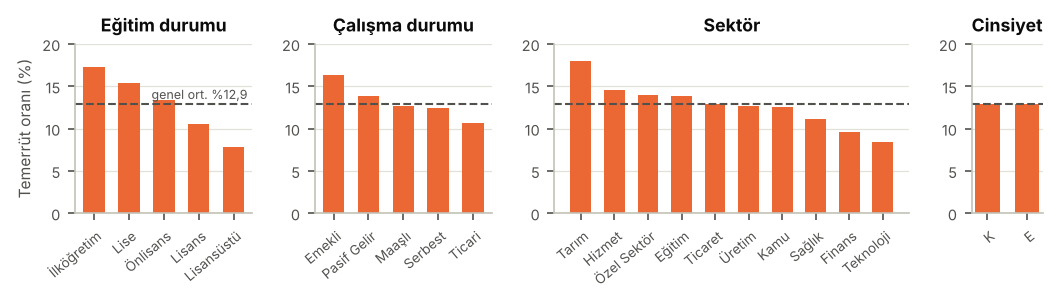

Şehirlere göre temerrüt oranı — en düşük 3 ve en yüksek 3:
          mean   size
Sehir                
Muğla     11.4   1958
İstanbul  11.7  18520
İzmir     11.8   7395
Malatya   16.2   1897
Van       16.4   1356
Mardin    17.1   1255

Cinsiyete göre temerrüt oranı (%): {'E': 12.89, 'K': 12.9}


In [8]:
# Grafik 4 — Kategorik değişkenlere göre temerrüt oranı
kategorikler = [("Egitim_Durumu", "Eğitim durumu"), ("Calisma_Durumu", "Çalışma durumu"),
                ("Sektor", "Sektör"), ("Cinsiyet", "Cinsiyet")]
fig, axes = plt.subplots(1, 4, figsize=(7.16, 2.05), gridspec_kw={"width_ratios": [5, 5, 10, 2]})
for ax, (col, ad) in zip(axes, kategorikler):
    oran = df.groupby(col).Temerrut.mean().sort_values(ascending=False) * 100
    ax.bar([str(i).replace("_", " ") for i in oran.index], oran.values, color=RENK_TEMERRUT, width=0.62)
    ax.axhline(genel_oran * 100, color="#52514e", ls="--", lw=1)
    ax.set_title(ad); ax.set_ylim(0, 20); ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=6.5)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
axes[0].set_ylabel("Temerrüt oranı (%)")
axes[0].text(4.4, genel_oran * 100 + 0.6, "genel ort. %12,9", fontsize=6, color="#52514e", ha="right")
fig.tight_layout()
kaydet(fig, "fig04_kategorik_temerrut_orani")

sehir_oran = df.groupby("Sehir").Temerrut.agg(["mean", "size"]).sort_values("mean")
print("Şehirlere göre temerrüt oranı — en düşük 3 ve en yüksek 3:")
print(pd.concat([sehir_oran.head(3), sehir_oran.tail(3)]).assign(mean=lambda d: (d["mean"] * 100).round(1)))
print("\nCinsiyete göre temerrüt oranı (%):", (df.groupby("Cinsiyet").Temerrut.mean() * 100).round(2).to_dict())

**Gözlemler:**
- **Eğitim düzeyi** yükseldikçe temerrüt oranı düşüyor (ilköğretim ≈ %17 → lisansüstü ≈ %8).
- **Emekliler** ve **tarım** sektörü daha riskli; **teknoloji** ve **finans** sektörleri daha az riskli.
- Şehirler arasındaki farklar küçük. Şehir zayıf ama potansiyel bir sinyal taşıyor.
- **Cinsiyete göre temerrüt oranı birebir aynı (≈ %12,9).** Cinsiyet hiçbir tahmin gücü taşımıyor. Üstelik kredi kararında cinsiyet kullanmak ayrımcılık ve adillik sorunu doğurur. Bu nedenle **`Cinsiyet` modelden çıkarılmıştır.**

Çarpıklık (skewness) — log1p öncesi ve sonrası:
                        önce  sonra
Aylik_Gelir_TL          1.44  -0.02
Kredi_Karti_Limiti_TL   1.22  -2.01
Kredi_Karti_Borcu_TL    1.87  -1.88
Kredi_Tutari_TL         1.44  -0.52
Aylik_Kredi_Odemesi_TL  2.84  -0.48
Toplam_Borc_TL          1.52  -1.31
Maksimum_Gecikme_Gunu   2.34   0.08


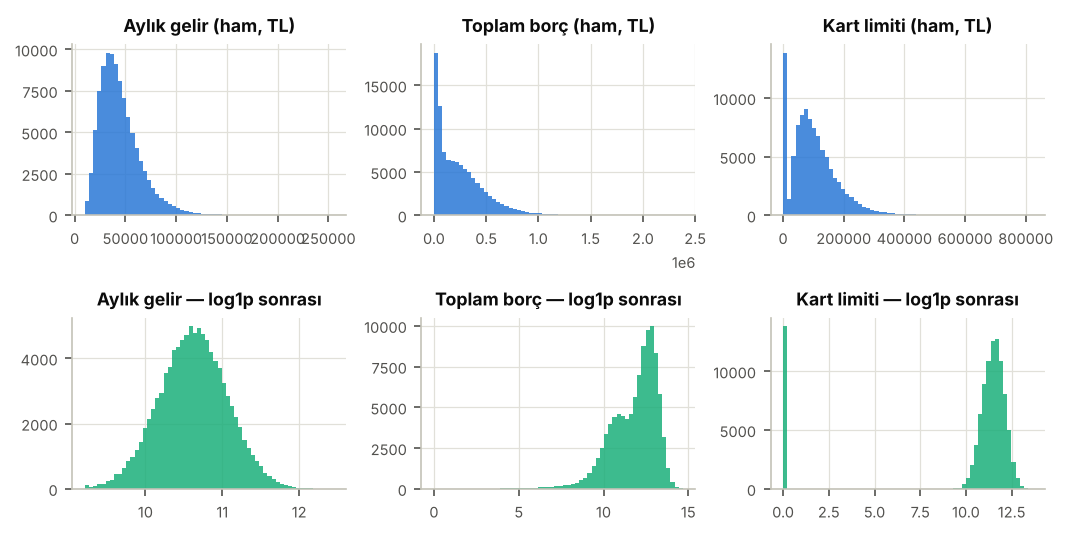

In [9]:
# Grafik 5 — Parasal değişkenlerdeki çarpıklık ve log dönüşümünün etkisi
LOG_COLS = ["Aylik_Gelir_TL", "Kredi_Karti_Limiti_TL", "Kredi_Karti_Borcu_TL", "Kredi_Tutari_TL",
            "Aylik_Kredi_Odemesi_TL", "Toplam_Borc_TL", "Maksimum_Gecikme_Gunu"]
print("Çarpıklık (skewness) — log1p öncesi ve sonrası:")
print(pd.DataFrame({"önce": df[LOG_COLS].skew(), "sonra": np.log1p(df[LOG_COLS]).skew()}).round(2))

fig, axes = plt.subplots(2, 3, figsize=(7.16, 3.6))
for j, (col, ad) in enumerate([("Aylik_Gelir_TL", "Aylık gelir"), ("Toplam_Borc_TL", "Toplam borç"),
                               ("Kredi_Karti_Limiti_TL", "Kart limiti")]):
    axes[0, j].hist(df[col], bins=60, color=RENK_ODEDI, alpha=0.85)
    axes[0, j].set_title(f"{ad} (ham, TL)")
    axes[1, j].hist(np.log1p(df[col]), bins=60, color="#1baf7a", alpha=0.85)
    axes[1, j].set_title(f"{ad} — log1p sonrası")
fig.tight_layout()
kaydet(fig, "fig05_log_donusumu")

In [10]:
# Aykırı değer incelemesi — IQR kuralı (Q1 − 1.5·IQR, Q3 + 1.5·IQR dışı)
q1, q3 = df[sayisal].quantile(0.25), df[sayisal].quantile(0.75)
iqr = q3 - q1
aykiri = ((df[sayisal] < q1 - 1.5 * iqr) | (df[sayisal] > q3 + 1.5 * iqr)).sum()
aykiri_tablo = pd.DataFrame({"aykırı_adet": aykiri, "aykırı_%": (aykiri / len(df) * 100).round(2)})
aykiri_tablo[aykiri_tablo.aykırı_adet > 0].sort_values("aykırı_adet", ascending=False)

,aykırı_adet,aykırı_%
Maksimum_Gecikme_Gunu,7390,7.39
Aktif_Urun_Sayisi,7016,7.02
Aylik_Kredi_Odemesi_TL,5030,5.03
Kredi_Karti_Borcu_TL,4281,4.28
Aylik_Borc_Odeme_Orani,4230,4.23
Aylik_Gelir_TL,3225,3.22
Kredi_Karti_Limiti_TL,2910,2.91
Toplam_Borc_TL,2386,2.39
Kredi_Tutari_TL,1839,1.84
Kredi_Gecmisi_Yil,1386,1.39


**Aykırı değer kararı:** IQR kuralının "aykırı" saydığı değerler (yüksek gelir, büyük kredi, 60+ gün gecikme gibi) bu veride **gerçek ve anlamlı** müşteri durumlarıdır. Hatalı ölçüm değildirler; özellikle yüksek gecikme günleri temerrüdün en güçlü habercilerindendir. Bu satırları **silmiyoruz**. Bunun yerine:
1. Çarpık parasal değişkenlere `log1p` dönüşümü uygulayarak uç değerlerin etkisini sıkıştırıyoruz.
2. Standartlaştırmadan sonra değerleri **[−5, +5] aralığına kırpıyoruz (clipping)**. Böylece aşırı uç bir girdi, sinir ağında büyük aktivasyonlara yol açamaz.

## 4. Veri Ön İşleme

| Adım | Uygulama | Gerekçe |
|---|---|---|
| Değişken çıkarma | `Musteri_ID`, `Musteri_Adi`, `Cinsiyet` atıldı | ID ve isim bilgi taşımaz, ezberlemeye yol açar; cinsiyet sinyal taşımaz ve etik açıdan sorunlu |
| Eksik değer | Gerekmedi | Veride eksik değer yok |
| Veri bölme | %70 eğitim / %15 doğrulama / %15 test, **stratified** | Sınıf oranı (%12,9) her parçada korunur; test seti yalnızca en sonda kullanılır |
| Log dönüşümü | 7 çarpık değişkene `log1p` | Sağa çarpık TL tutarlarını simetrik hale getirir |
| Ölçekleme | `StandardScaler` mantığı: (x − μ) / σ | Sinir ağı farklı ölçekteki girdilerde kararsız öğrenir. μ ve σ **yalnızca eğitim setinden** hesaplanır (veri sızıntısı önlenir) |
| Kırpma | Standart değerler [−5, 5] | Uç değerlerin etkisini sınırlar |
| Encoding | Kategoriler → tam sayı indeks → **Embedding** katmanı | One-hot yerine öğrenilebilir yoğun vektörler; 30 şehir için 30 sütun açmak yerine 16 boyutlu temsil. İndeks 0, eğitimde görülmemiş kategoriler için ayrıldı |

Görüntü verisine özgü adımlar (yeniden boyutlandırma, veri artırma) tablo verisinde uygulanmaz.

In [11]:
# Modelde kullanılacak değişkenler
CAT_COLS = ["Egitim_Durumu", "Sehir", "Calisma_Durumu", "Sektor"]
NUM_COLS = ["Yas", "Aylik_Gelir_TL", "Calisma_Suresi_Yil", "Banka_Musterilik_Suresi_Ay", "Aktif_Urun_Sayisi",
            "Dijital_Bankacilik_Kullanim_Skoru", "Kredi_Gecmisi_Yil", "Kredi_Skoru",
            "Kredi_Karti_Limiti_TL", "Kredi_Karti_Kullanim_Orani", "Kredi_Karti_Borcu_TL",
            "Kredi_Tutari_TL", "Kredi_Vadesi_Ay", "Aylik_Kredi_Odemesi_TL",
            "Toplam_Borc_TL", "Borc_Gelir_Orani", "Aylik_Borc_Odeme_Orani",
            "Son_12_Ay_Odeme_Orani", "Gec_Odeme_Sayisi_12_Ay", "Maksimum_Gecikme_Gunu"]
TARGET = "Temerrut"
print(f"{len(NUM_COLS)} sayısal + {len(CAT_COLS)} kategorik = {len(NUM_COLS) + len(CAT_COLS)} değişken")

20 sayısal + 4 kategorik = 24 değişken


In [12]:
# Stratified bölme: önce %70 eğitim / %30 geçici, sonra geçiciyi ikiye -> %15 doğrulama, %15 test
y_all = df[TARGET].values
idx_all = np.arange(len(df))
idx_train, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=y_all, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp], random_state=SEED)

df_train, df_val, df_test = df.iloc[idx_train], df.iloc[idx_val], df.iloc[idx_test]
for ad, parca in [("Eğitim", df_train), ("Doğrulama", df_val), ("Test", df_test)]:
    print(f"{ad:10s}: {len(parca):6,} satır | temerrüt oranı = %{parca[TARGET].mean()*100:.2f}")

Eğitim    : 70,000 satır | temerrüt oranı = %12.90
Doğrulama : 15,000 satır | temerrüt oranı = %12.90
Test      : 15,000 satır | temerrüt oranı = %12.89


In [13]:
def on_isleyici_ogren(egitim_df):
    """Ön işleme parametrelerini YALNIZCA eğitim verisinden öğrenir.
    Sözlük olarak döner -> JSON'a yazılıp uygulamada aynen kullanılabilir."""
    X = egitim_df[NUM_COLS].astype(float).copy()
    for c in LOG_COLS:
        X[c] = np.log1p(X[c])
    return {
        "num_cols": NUM_COLS, "cat_cols": CAT_COLS, "log_cols": LOG_COLS,
        "mean": X.mean().tolist(), "std": X.std().tolist(), "clip": 5.0,
        # Her kategori için sözlük; indeks 0 = bilinmeyen kategori
        "vocab": {c: sorted(egitim_df[c].unique().tolist()) for c in CAT_COLS},
    }

def on_isle(veri, prep):
    """Bir DataFrame'i modele girecek iki tensöre çevirir: sayısal (float) ve kategorik (indeks)."""
    X = veri[prep["num_cols"]].astype(float).copy()
    for c in prep["log_cols"]:
        X[c] = np.log1p(X[c])
    X = (X.values - np.array(prep["mean"])) / np.array(prep["std"])
    X = np.clip(X, -prep["clip"], prep["clip"]).astype(np.float32)
    C = np.stack([veri[c].map({v: i + 1 for i, v in enumerate(prep["vocab"][c])}).fillna(0).astype(int).values
                  for c in prep["cat_cols"]], axis=1)
    return torch.tensor(X), torch.tensor(C, dtype=torch.long)

prep = on_isleyici_ogren(df_train)
Xn_tr, Xc_tr = on_isle(df_train, prep)
Xn_va, Xc_va = on_isle(df_val, prep)
Xn_te, Xc_te = on_isle(df_test, prep)
y_tr = torch.tensor(df_train[TARGET].values, dtype=torch.float32)
y_va = torch.tensor(df_val[TARGET].values, dtype=torch.float32)
y_te = torch.tensor(df_test[TARGET].values, dtype=torch.float32)

CAT_CARDS = [len(prep["vocab"][c]) + 1 for c in CAT_COLS]   # +1: bilinmeyen kategori
print("Sayısal tensör:", tuple(Xn_tr.shape), "| Kategorik tensör:", tuple(Xc_tr.shape))
print("Kategori sayıları (bilinmeyen dahil):", dict(zip(CAT_COLS, CAT_CARDS)))
print("Ölçeklenmiş eğitim verisi -> ortalama ≈ 0, std ≈ 1:", Xn_tr.mean().item().__round__(3), Xn_tr.std().item().__round__(3))

Sayısal tensör: (70000, 20) | Kategorik tensör: (70000, 4)
Kategori sayıları (bilinmeyen dahil): {'Egitim_Durumu': 6, 'Sehir': 31, 'Calisma_Durumu': 6, 'Sektor': 11}
Ölçeklenmiş eğitim verisi -> ortalama ≈ 0, std ≈ 1: 0.0 0.999


## 5. Model Tasarımı: Feature Tokenizer + 1D-CNN

### Neden doğrudan CNN değil?
CNN'ler **yerellik** varsayımıyla çalışır: görüntüde yan yana pikseller birbiriyle ilişkilidir ve aynı filtre görüntünün her yerinde işe yarar. Tablo verisinde ise sütun sırası keyfidir. Bu yüzden CNN'i ham satıra uygulamak anlamsızdır. Veriyi önce evrişimin anlamlı olacağı bir yapıya dönüştürüyoruz:

1. **Feature Tokenizer:** Her değişken 16 boyutlu bir "token" vektörüne dönüştürülür. Sayısal değişkenlerin her biri kendi öğrenilebilir ağırlık ve bias vektörüyle (`x·w + b`), kategorik değişkenler ise **Embedding** tablosuyla temsil edilir. Sonuçta her müşteri **24 token × 16 kanallık** bir diziye dönüşür. Bu, 1D bir "sinyal" gibi düşünülebilir.
2. **Anlamsal sıralama:** Tokenlar ilişkili değişkenler yan yana gelecek şekilde dizilir:
   `Demografi → İş/Gelir → Banka ilişkisi → Kredi geçmişi → Kredi kartı → Kredi → Borç yükü → Ödeme davranışı`.
   Böylece 3 genişlikli evrişim penceresi, örneğin *limit–kullanım oranı–kart borcu* üçlüsünü birlikte görür ve aralarındaki **yerel etkileşimleri** öğrenebilir.
3. **Evrişim blokları:** `Conv1d → BatchNorm → ReLU` (3 blok, 32→64→64 kanal, kernel=3, padding=1). Üçüncü blokta **artık (residual) bağlantı** vardır; derin katmanlarda gradyan akışını kolaylaştırır.
4. **Global Average + Max Pooling:** Dizinin ortalaması (genel risk resmi) ve maksimumu (en güçlü tekil risk sinyali) birleştirilir → 128 boyut.
5. **Sınıflandırma başlığı:** `Linear(128→64) → ReLU → Dropout(0,3) → Linear(64→1)`. Çıktı tek bir **logit**'tir.

| Bileşen | Seçim | Gerekçe |
|---|---|---|
| Aktivasyon | ReLU | Basit, hızlı, kaybolan gradyan sorunu yok |
| Normalizasyon | BatchNorm1d | Eğitimi hızlandırır ve kararlı kılar |
| Düzenlileştirme | Dropout 0,3 + weight decay 1e-4 + erken durdurma | Ezberlemeyi önler |
| Loss | `BCEWithLogitsLoss(pos_weight = n₀/n₁ ≈ 6,75)` | İkili sınıflandırma; azınlık sınıfının hataları ~6,75 kat cezalandırılır. Sigmoid loss içinde uygulandığı için sayısal olarak kararlıdır |
| Optimizer | AdamW (lr = 1e-3) | Uyarlanabilir öğrenme oranı; weight decay doğru şekilde ayrıştırılmış |
| LR planı | ReduceLROnPlateau (faktör 0,5, sabır 2) | Doğrulama başarısı durunca öğrenme oranını yarıya indirir |

**Kıyas modelleri:** Evrişimin gerçekten katkı yapıp yapmadığını görmek için aynı tokenizer'ı kullanan bir **MLP** ve tokenları **rastgele sıraya dizilmiş bir CNN** (ablasyon) de eğitilecek. Ayrıca klasik ML referansı olarak **Lojistik Regresyon** ve **Gradient Boosting** kullanılacak.

In [14]:
# Token sırası: ilişkili değişkenler yan yana (evrişim penceresi bunları birlikte görür)
TOKEN_SIRASI = [
    "Yas", "Egitim_Durumu", "Sehir",                                                   # demografi
    "Calisma_Durumu", "Sektor", "Aylik_Gelir_TL", "Calisma_Suresi_Yil",                # iş ve gelir
    "Banka_Musterilik_Suresi_Ay", "Aktif_Urun_Sayisi", "Dijital_Bankacilik_Kullanim_Skoru",  # banka ilişkisi
    "Kredi_Gecmisi_Yil", "Kredi_Skoru",                                                # kredi geçmişi
    "Kredi_Karti_Limiti_TL", "Kredi_Karti_Kullanim_Orani", "Kredi_Karti_Borcu_TL",     # kredi kartı
    "Kredi_Tutari_TL", "Kredi_Vadesi_Ay", "Aylik_Kredi_Odemesi_TL",                    # kredi
    "Toplam_Borc_TL", "Borc_Gelir_Orani", "Aylik_Borc_Odeme_Orani",                    # borç yükü
    "Son_12_Ay_Odeme_Orani", "Gec_Odeme_Sayisi_12_Ay", "Maksimum_Gecikme_Gunu",       # ödeme davranışı
]
# Tokenizer çıktısında önce sayısallar sonra kategorikler gelir; bu listeye göre yeniden dizeceğiz
TUM_DEGISKENLER = NUM_COLS + CAT_COLS
SIRA_INDEKS = [TUM_DEGISKENLER.index(ad) for ad in TOKEN_SIRASI]
assert sorted(SIRA_INDEKS) == list(range(len(TUM_DEGISKENLER)))


class FeatureTokenizer(nn.Module):
    """Her değişkeni d boyutlu bir token vektörüne dönüştürür."""
    def __init__(self, n_num, cat_cards, d):
        super().__init__()
        # Sayısal değişken i için: token_i = x_i * w_i + b_i   (w_i, b_i ∈ R^d öğrenilir)
        self.num_w = nn.Parameter(torch.randn(n_num, d) * 0.1)
        self.num_b = nn.Parameter(torch.zeros(n_num, d))
        # Kategorik değişkenler için birer embedding tablosu
        self.embs = nn.ModuleList([nn.Embedding(k, d) for k in cat_cards])

    def forward(self, x_num, x_cat):
        t_num = x_num.unsqueeze(-1) * self.num_w + self.num_b                       # (B, 20, d)
        t_cat = torch.stack([emb(x_cat[:, i]) for i, emb in enumerate(self.embs)], 1)  # (B, 4, d)
        return torch.cat([t_num, t_cat], dim=1)                                      # (B, 24, d)


def conv_blok(giris, cikis):
    """Conv1d -> BatchNorm -> ReLU. kernel=3 ve padding=1 ile dizi uzunluğu korunur."""
    return nn.Sequential(nn.Conv1d(giris, cikis, kernel_size=3, padding=1),
                         nn.BatchNorm1d(cikis), nn.ReLU())


class TabularCNN(nn.Module):
    def __init__(self, n_num, cat_cards, token_sirasi, d=16, dropout=0.3):
        super().__init__()
        self.tokenizer = FeatureTokenizer(n_num, cat_cards, d)
        self.register_buffer("token_sirasi", torch.as_tensor(token_sirasi))  # öğrenilmez, modelle kaydedilir
        self.conv1 = conv_blok(d, 32)
        self.conv2 = conv_blok(32, 64)
        self.conv3 = conv_blok(64, 64)
        self.head = nn.Sequential(nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, x_num, x_cat):
        t = self.tokenizer(x_num, x_cat)[:, self.token_sirasi]   # (B, 24, d) — anlamsal sıra
        x = t.transpose(1, 2)                                    # Conv1d (B, kanal, uzunluk) bekler
        x = self.conv2(self.conv1(x))                            # (B, 64, 24)
        x = x + self.conv3(x)                                    # residual bağlantı
        x = torch.cat([x.mean(dim=2), x.amax(dim=2)], dim=1)     # global avg ⊕ max pooling -> (B, 128)
        return self.head(x).squeeze(1)                           # logit (B,)


class TabularMLP(nn.Module):
    """Kıyas modeli: aynı tokenizer, ama evrişim yerine tokenlar düzleştirilip tam bağlı katmanlara verilir."""
    def __init__(self, n_num, cat_cards, d=16, dropout=0.3):
        super().__init__()
        self.tokenizer = FeatureTokenizer(n_num, cat_cards, d)
        n_token = n_num + len(cat_cards)
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(n_token * d, 128), nn.BatchNorm1d(128), nn.ReLU(),
                                 nn.Dropout(dropout), nn.Linear(128, 64), nn.ReLU(),
                                 nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, x_num, x_cat):
        return self.net(self.tokenizer(x_num, x_cat)).squeeze(1)


def parametre_sayisi(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print(TabularCNN(len(NUM_COLS), CAT_CARDS, SIRA_INDEKS))
print(f"\nTabularCNN parametre sayısı: {parametre_sayisi(TabularCNN(len(NUM_COLS), CAT_CARDS, SIRA_INDEKS)):,}")
print(f"TabularMLP parametre sayısı: {parametre_sayisi(TabularMLP(len(NUM_COLS), CAT_CARDS)):,}")

TabularCNN(
  (tokenizer): FeatureTokenizer(
    (embs): ModuleList(
      (0): Embedding(6, 16)
      (1): Embedding(31, 16)
      (2): Embedding(6, 16)
      (3): Embedding(11, 16)
    )
  )
  (conv1): Sequential(
    (0): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (conv2): Sequential(
    (0): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (conv3): Sequential(
    (0): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, o

## 6. Model Eğitimi

- **Eğitim/doğrulama yaklaşımı:** Model eğitim setinde (%70) öğrenir. Her epoch sonunda doğrulama setinde (%15) değerlendirilir. Test seti (%15) eğitim boyunca **hiç görülmez**.
- **Batch size = 512:** 70 bin satır için epoch başına ~137 adım; gradyan gürültüsü düşük ve CPU'da hızlı.
- **Epoch:** En fazla 40. Erken durdurma doğrulama **PR-AUC**'sine bakar. Dengesiz veride ROC-AUC'den daha bilgilendiricidir, çünkü azınlık sınıfındaki başarıya odaklanır. 6 epoch boyunca iyileşme olmazsa eğitim durur ve **en iyi epoch'un ağırlıkları geri yüklenir**.
- **Olasılık düzeltmesi:** `pos_weight = w` ile eğitilen model, temerrüt olasılığını sistematik olarak **abartır**. Modelin öğrendiği oran, gerçek oranın `w` katıdır. Bunu teorik olarak tam düzeltmek için logitten `ln(w)` çıkarıyoruz: `p = σ(z − ln w)`. Böylece uygulamada gösterilen olasılık gerçekçi olur. Kalibrasyon grafiği ile bu doğrulanacak.

In [15]:
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
LOG_PW = float(torch.log(pos_weight))
print(f"pos_weight = {pos_weight:.3f}  ->  olasılık düzeltmesi: logit − ln(w) = logit − {LOG_PW:.3f}")

kayip_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))
BATCH_SIZE, MAX_EPOCH, SABIR = 512, 40, 6

def yukleyici(seed=SEED):
    g = torch.Generator().manual_seed(seed)   # karıştırma sırası da tekrarlanabilir olsun
    return DataLoader(TensorDataset(Xn_tr, Xc_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True, generator=g)

@torch.no_grad()
def logit_tahmin(model, Xn, Xc, bs=4096):
    model.eval()
    return torch.cat([model(Xn[i:i+bs].to(DEVICE), Xc[i:i+bs].to(DEVICE)).cpu() for i in range(0, len(Xn), bs)])

def olasilik(model, Xn, Xc):
    """Kalibre edilmiş temerrüt olasılığı: σ(logit − ln w)."""
    return torch.sigmoid(logit_tahmin(model, Xn, Xc) - LOG_PW).numpy()

def egit(model, ad, lr=1e-3, weight_decay=1e-4):
    set_seed()
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    loader = yukleyici()
    gecmis, en_iyi_ap, en_iyi_durum, bekleme = [], -1.0, None, 0
    t0 = time.time()
    for epoch in range(1, MAX_EPOCH + 1):
        # --- Eğitim adımı ---
        model.train(); toplam_kayip = 0.0
        for xn, xc, yb in loader:
            xn, xc, yb = xn.to(DEVICE), xc.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            kayip = kayip_fn(model(xn, xc), yb)
            kayip.backward()
            opt.step()
            toplam_kayip += kayip.item() * len(yb)
        # --- Doğrulama adımı ---
        val_logit = logit_tahmin(model, Xn_va, Xc_va)
        val_kayip = kayip_fn(val_logit.to(DEVICE), y_va.to(DEVICE)).item()
        val_p = torch.sigmoid(val_logit - LOG_PW).numpy()
        ap, auc = average_precision_score(y_va, val_p), roc_auc_score(y_va, val_p)
        sched.step(ap)
        gecmis.append({"epoch": epoch, "egitim_kayip": toplam_kayip / len(y_tr), "dogrulama_kayip": val_kayip,
                       "val_pr_auc": ap, "val_roc_auc": auc, "lr": opt.param_groups[0]["lr"]})
        # --- Erken durdurma: en iyi PR-AUC'yi sakla ---
        if ap > en_iyi_ap + 1e-4:
            en_iyi_ap, en_iyi_durum, bekleme, isaret = ap, copy.deepcopy(model.state_dict()), 0, "*"
        else:
            bekleme += 1; isaret = ""
        print(f"[{ad}] epoch {epoch:2d} | eğitim kaybı {gecmis[-1]['egitim_kayip']:.4f} | "
              f"doğrulama kaybı {val_kayip:.4f} | val PR-AUC {ap:.4f} | val ROC-AUC {auc:.4f} {isaret}")
        if bekleme >= SABIR:
            print(f"[{ad}] Erken durdurma: {SABIR} epoch boyunca iyileşme yok.")
            break
    model.load_state_dict(en_iyi_durum)
    gecmis = pd.DataFrame(gecmis)
    en_iyi_epoch = int(gecmis.val_pr_auc.idxmax()) + 1
    print(f"[{ad}] Süre: {time.time()-t0:.0f} sn | en iyi epoch: {en_iyi_epoch} | en iyi val PR-AUC: {en_iyi_ap:.4f}")
    return model, gecmis

pos_weight = 6.753  ->  olasılık düzeltmesi: logit − ln(w) = logit − 1.910


In [16]:
# Ana model: anlamsal token sırasıyla 1D-CNN
cnn, gecmis_cnn = egit(TabularCNN(len(NUM_COLS), CAT_CARDS, SIRA_INDEKS), "CNN")

[CNN] epoch  1 | eğitim kaybı 0.8740 | doğrulama kaybı 0.6039 | val PR-AUC 0.7045 | val ROC-AUC 0.9282 *


[CNN] epoch  2 | eğitim kaybı 0.6097 | doğrulama kaybı 0.5975 | val PR-AUC 0.7058 | val ROC-AUC 0.9289 *


[CNN] epoch  3 | eğitim kaybı 0.6015 | doğrulama kaybı 0.5916 | val PR-AUC 0.7085 | val ROC-AUC 0.9293 *


[CNN] epoch  4 | eğitim kaybı 0.5947 | doğrulama kaybı 0.5939 | val PR-AUC 0.7075 | val ROC-AUC 0.9285 


[CNN] epoch  5 | eğitim kaybı 0.5886 | doğrulama kaybı 0.5871 | val PR-AUC 0.7105 | val ROC-AUC 0.9296 *


...

[CNN] epoch  7 | eğitim kaybı 0.5842 | doğrulama kaybı 0.5955 | val PR-AUC 0.7095 | val ROC-AUC 0.9284 


[CNN] epoch  8 | eğitim kaybı 0.5781 | doğrulama kaybı 0.5983 | val PR-AUC 0.7097 | val ROC-AUC 0.9290 


[CNN] epoch  9 | eğitim kaybı 0.5702 | doğrulama kaybı 0.5986 | val PR-AUC 0.7097 | val ROC-AUC 0.9278 


[CNN] epoch 10 | eğitim kaybı 0.5647 | doğrulama kaybı 0.5968 | val PR-AUC 0.7082 | val ROC-AUC 0.9278 


[CNN] epoch 11 | eğitim kaybı 0.5602 | doğrulama kaybı 0.6164 | val PR-AUC 0.7056 | val ROC-AUC 0.9251 
[CNN] Erken durdurma: 6 epoch boyunca iyileşme yok.
[CNN] Süre: 59 sn | en iyi epoch: 5 | en iyi val PR-AUC: 0.7105


In [17]:
# Ablasyon 1: aynı tokenizer + MLP (evrişim yok)
mlp, gecmis_mlp = egit(TabularMLP(len(NUM_COLS), CAT_CARDS), "MLP")

[MLP] epoch  1 | eğitim kaybı 0.7020 | doğrulama kaybı 0.5929 | val PR-AUC 0.7047 | val ROC-AUC 0.9287 *


[MLP] epoch  2 | eğitim kaybı 0.6060 | doğrulama kaybı 0.5887 | val PR-AUC 0.7100 | val ROC-AUC 0.9299 *


[MLP] epoch  3 | eğitim kaybı 0.5970 | doğrulama kaybı 0.5899 | val PR-AUC 0.7078 | val ROC-AUC 0.9295 


[MLP] epoch  4 | eğitim kaybı 0.5919 | doğrulama kaybı 0.5900 | val PR-AUC 0.7091 | val ROC-AUC 0.9291 


[MLP] epoch  5 | eğitim kaybı 0.5884 | doğrulama kaybı 0.5916 | val PR-AUC 0.7118 | val ROC-AUC 0.9294 *


...

[MLP] epoch  7 | eğitim kaybı 0.5874 | doğrulama kaybı 0.5909 | val PR-AUC 0.7084 | val ROC-AUC 0.9289 


[MLP] epoch  8 | eğitim kaybı 0.5838 | doğrulama kaybı 0.5926 | val PR-AUC 0.7109 | val ROC-AUC 0.9295 


[MLP] epoch  9 | eğitim kaybı 0.5797 | doğrulama kaybı 0.5863 | val PR-AUC 0.7111 | val ROC-AUC 0.9299 


[MLP] epoch 10 | eğitim kaybı 0.5795 | doğrulama kaybı 0.5872 | val PR-AUC 0.7104 | val ROC-AUC 0.9298 


[MLP] epoch 11 | eğitim kaybı 0.5770 | doğrulama kaybı 0.5889 | val PR-AUC 0.7097 | val ROC-AUC 0.9293 
[MLP] Erken durdurma: 6 epoch boyunca iyileşme yok.
[MLP] Süre: 13 sn | en iyi epoch: 5 | en iyi val PR-AUC: 0.7118


In [18]:
# Ablasyon 2: aynı CNN, ama tokenlar RASTGELE sırada -> anlamsal sıralamanın katkısını ölçer
rastgele_sira = list(np.random.default_rng(7).permutation(len(TUM_DEGISKENLER)))
print("Rastgele sıra:", [TUM_DEGISKENLER[i] for i in rastgele_sira][:6], "...")
cnn_rastgele, gecmis_cnn_r = egit(TabularCNN(len(NUM_COLS), CAT_CARDS, rastgele_sira), "CNN-rastgele")

Rastgele sıra: ['Borc_Gelir_Orani', 'Aktif_Urun_Sayisi', 'Gec_Odeme_Sayisi_12_Ay', 'Banka_Musterilik_Suresi_Ay', 'Toplam_Borc_TL', 'Kredi_Vadesi_Ay'] ...


[CNN-rastgele] epoch  1 | eğitim kaybı 0.8125 | doğrulama kaybı 0.6045 | val PR-AUC 0.6970 | val ROC-AUC 0.9259 *


[CNN-rastgele] epoch  2 | eğitim kaybı 0.6173 | doğrulama kaybı 0.6078 | val PR-AUC 0.7028 | val ROC-AUC 0.9269 *


[CNN-rastgele] epoch  3 | eğitim kaybı 0.6049 | doğrulama kaybı 0.5877 | val PR-AUC 0.7105 | val ROC-AUC 0.9298 *


[CNN-rastgele] epoch  4 | eğitim kaybı 0.5959 | doğrulama kaybı 0.5902 | val PR-AUC 0.7085 | val ROC-AUC 0.9290 


...

[CNN-rastgele] epoch 11 | eğitim kaybı 0.5629 | doğrulama kaybı 0.6005 | val PR-AUC 0.7092 | val ROC-AUC 0.9274 


[CNN-rastgele] epoch 12 | eğitim kaybı 0.5615 | doğrulama kaybı 0.6011 | val PR-AUC 0.7091 | val ROC-AUC 0.9282 


[CNN-rastgele] epoch 13 | eğitim kaybı 0.5501 | doğrulama kaybı 0.5985 | val PR-AUC 0.7095 | val ROC-AUC 0.9278 


[CNN-rastgele] epoch 14 | eğitim kaybı 0.5431 | doğrulama kaybı 0.5998 | val PR-AUC 0.7097 | val ROC-AUC 0.9280 


[CNN-rastgele] epoch 15 | eğitim kaybı 0.5441 | doğrulama kaybı 0.6017 | val PR-AUC 0.7093 | val ROC-AUC 0.9274 
[CNN-rastgele] Erken durdurma: 6 epoch boyunca iyileşme yok.
[CNN-rastgele] Süre: 79 sn | en iyi epoch: 9 | en iyi val PR-AUC: 0.7121


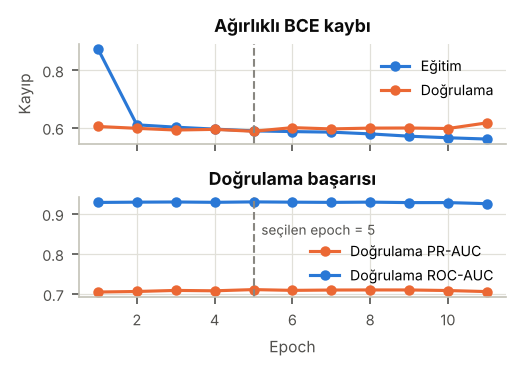

In [19]:
# Grafik 6 — Eğitim eğrileri (ana CNN)
en_iyi = int(gecmis_cnn.val_pr_auc.idxmax()) + 1
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(3.5, 2.5), sharex=True)
ax1.plot(gecmis_cnn.epoch, gecmis_cnn.egitim_kayip, color=RENK_ODEDI, marker="o", label="Eğitim")
ax1.plot(gecmis_cnn.epoch, gecmis_cnn.dogrulama_kayip, color=RENK_TEMERRUT, marker="o", label="Doğrulama")
ax1.set_title("Ağırlıklı BCE kaybı"); ax1.set_ylabel("Kayıp"); ax1.legend()
ax2.plot(gecmis_cnn.epoch, gecmis_cnn.val_pr_auc, color=RENK_TEMERRUT, marker="o", label="Doğrulama PR-AUC")
ax2.plot(gecmis_cnn.epoch, gecmis_cnn.val_roc_auc, color=RENK_ODEDI, marker="o", label="Doğrulama ROC-AUC")
for ax in (ax1, ax2):
    ax.axvline(en_iyi, color="#898781", ls="--", lw=1)
ax2.text(en_iyi + 0.2, 0.86, f"seçilen epoch = {en_iyi}", color="#52514e", fontsize=6.5, va="center")
ax2.set_title("Doğrulama başarısı"); ax2.set_xlabel("Epoch"); ax2.legend(loc="lower right")
fig.tight_layout()
kaydet(fig, "fig06_egitim_egrileri")

**Klasik ML referansları:** Lojistik Regresyon (one-hot + aynı ölçekleme) ve Histogram Gradient Boosting (kategorikleri doğal olarak işler). Bunlar derin öğrenme modelinin hangi seviyede durduğunu anlamak için kullanılır.

In [20]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(Xc_tr.numpy())
X_lr = lambda Xn, Xc: np.hstack([Xn.numpy(), ohe.transform(Xc.numpy())])

t0 = time.time()
logreg = LogisticRegression(max_iter=3000, class_weight="balanced").fit(X_lr(Xn_tr, Xc_tr), y_tr.numpy())
print(f"Lojistik Regresyon eğitildi ({time.time()-t0:.1f} sn)")

X_hgb = lambda Xn, Xc: np.hstack([Xn.numpy(), Xc.numpy()])
t0 = time.time()
hgb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                     categorical_features=list(range(len(NUM_COLS), len(NUM_COLS) + len(CAT_COLS))),
                                     early_stopping=True, validation_fraction=0.1, random_state=SEED)
hgb.fit(X_hgb(Xn_tr, Xc_tr), y_tr.numpy())
print(f"Gradient Boosting eğitildi ({time.time()-t0:.1f} sn, {hgb.n_iter_} ağaç)")

# class_weight='balanced' de olasılığı abartır -> aynı ln(w) düzeltmesini uygulayalım
def p_logreg(Xn, Xc):
    z = logreg.decision_function(X_lr(Xn, Xc))
    return 1 / (1 + np.exp(-(z - LOG_PW)))
p_hgb = lambda Xn, Xc: hgb.predict_proba(X_hgb(Xn, Xc))[:, 1]

Lojistik Regresyon eğitildi (0.8 sn)


Gradient Boosting eğitildi (1.8 sn, 134 ağaç)


## 7. Model Değerlendirme

**Eşik seçimi:** Modelin olasılık çıktısını karara çevirecek eşik, **doğrulama setinde F1'i en yüksek yapan değer** olarak seçilir. Test seti eşik seçiminde kullanılmaz, yoksa sonuçlar iyimser çıkar. Aynı prosedür bütün modellere uygulanır.

In [21]:
ESIKLER = np.round(np.arange(0.05, 0.951, 0.01), 2)

def esik_sec(y, p):
    f1s = [f1_score(y, p >= t, zero_division=0) for t in ESIKLER]
    return float(ESIKLER[int(np.argmax(f1s))])

def metrikler(y, p, esik):
    tahmin = (p >= esik).astype(int)
    return {"Eşik": esik, "Accuracy": accuracy_score(y, tahmin),
            "Precision": precision_score(y, tahmin, zero_division=0), "Recall": recall_score(y, tahmin),
            "F1": f1_score(y, tahmin), "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}

modeller = {
    "1D-CNN (anlamsal sıra)":  lambda Xn, Xc: olasilik(cnn, Xn, Xc),
    "1D-CNN (rastgele sıra)":  lambda Xn, Xc: olasilik(cnn_rastgele, Xn, Xc),
    "MLP (aynı tokenizer)":    lambda Xn, Xc: olasilik(mlp, Xn, Xc),
    "Lojistik Regresyon":      p_logreg,
    "Gradient Boosting":       p_hgb,
}
y_val_np, y_test_np = y_va.numpy().astype(int), y_te.numpy().astype(int)
sonuclar, test_olasilik = [], {}
for ad, f in modeller.items():
    esik = esik_sec(y_val_np, f(Xn_va, Xc_va))          # eşik doğrulamadan
    test_olasilik[ad] = f(Xn_te, Xc_te)                 # metrikler testten
    sonuclar.append({"Model": ad, **metrikler(y_test_np, test_olasilik[ad], esik)})
# Naif taban: herkese "ödüyor" demek
sonuclar.append({"Model": "Naif taban (hep 0)", "Eşik": np.nan, "Accuracy": 1 - y_test_np.mean(),
                 "Precision": 0.0, "Recall": 0.0, "F1": 0.0, "ROC-AUC": 0.5, "PR-AUC": y_test_np.mean()})
sonuc_tablo = pd.DataFrame(sonuclar).set_index("Model")
sonuc_tablo.style.format("{:.4f}").format("{:.2f}", subset=["Eşik"]).highlight_max(
    axis=0, subset=["F1", "ROC-AUC", "PR-AUC"], props="font-weight:bold")

,Eşik,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,,
1D-CNN (anlamsal sıra),0.39,0.9093,0.6538,0.6298,0.6416,0.9287,0.7027
1D-CNN (rastgele sıra),0.35,0.9095,0.6550,0.6293,0.6419,0.9271,0.7014
MLP (aynı tokenizer),0.36,0.9023,0.6083,0.6810,0.6426,0.9278,0.7006
Lojistik Regresyon,0.34,0.9068,0.6309,0.6680,0.6489,0.9295,0.7040
Gradient Boosting,0.38,0.9082,0.6453,0.6396,0.6424,0.9273,0.6971
Naif taban (hep 0),nan,0.8711,0.0000,0.0000,0.0000,0.5000,0.1289


In [22]:
# Ana modelin test sonuçları
ESIK = float(sonuc_tablo.loc["1D-CNN (anlamsal sıra)", "Eşik"])
p_test = test_olasilik["1D-CNN (anlamsal sıra)"]
tahmin_test = (p_test >= ESIK).astype(int)
print(f"Seçilen karar eşiği (doğrulamadan): {ESIK:.2f}")
for k, v in sonuc_tablo.loc["1D-CNN (anlamsal sıra)"].items():
    print(f"  {k:10s}: {v:.4f}")

Seçilen karar eşiği (doğrulamadan): 0.39
  Eşik      : 0.3900
  Accuracy  : 0.9093
  Precision : 0.6538
  Recall    : 0.6298
  F1        : 0.6416
  ROC-AUC   : 0.9287
  PR-AUC    : 0.7027


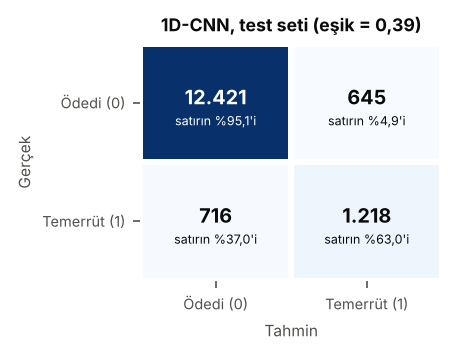

TN=12,421  FP=645  FN=716  TP=1,218


In [23]:
# Grafik 7 — Confusion matrix (ana CNN, test seti)
cm = confusion_matrix(y_test_np, tahmin_test)
fig, ax = plt.subplots(figsize=(2.6, 2.05))
sns.heatmap(cm, annot=False, cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white")
satir_toplam = cm.sum(axis=1, keepdims=True)
for i in range(2):
    for j in range(2):
        renk = "white" if cm[i, j] > cm.max() * 0.5 else "#0b0b0b"
        ax.text(j + 0.5, i + 0.45, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=9.5, fontweight="bold", color=renk)
        ax.text(j + 0.5, i + 0.65, f"satırın %{cm[i, j] / satir_toplam[i, 0] * 100:.1f}'i".replace(".", ","), ha="center", va="center", fontsize=6, color=renk)
ax.set_xticklabels(["Ödedi (0)", "Temerrüt (1)"]); ax.set_yticklabels(["Ödedi (0)", "Temerrüt (1)"], rotation=0)
ax.set_xlabel("Tahmin"); ax.set_ylabel("Gerçek")
ax.set_title(f"1D-CNN, test seti (eşik = {ESIK:.2f})".replace(".", ","))
kaydet(fig, "fig07_confusion_matrix")
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

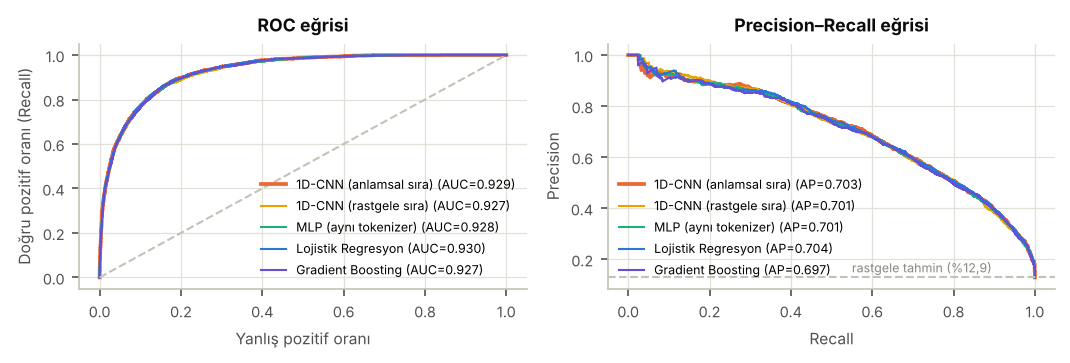

In [24]:
# Grafik 8 — ROC ve Precision-Recall eğrileri (tüm modeller)
renkler = {"1D-CNN (anlamsal sıra)": "#eb6834", "1D-CNN (rastgele sıra)": "#eda100", "MLP (aynı tokenizer)": "#1baf7a",
           "Lojistik Regresyon": "#2a78d6", "Gradient Boosting": "#6250d6"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.16, 2.45))
for ad, p in test_olasilik.items():
    kalin = 1.8 if ad.startswith("1D-CNN (anlamsal") else 1.0
    fpr, tpr, _ = roc_curve(y_test_np, p)
    ax1.plot(fpr, tpr, color=renkler[ad], lw=kalin, label=f"{ad} (AUC={roc_auc_score(y_test_np, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test_np, p)
    ax2.plot(rc, pr, color=renkler[ad], lw=kalin, label=f"{ad} (AP={average_precision_score(y_test_np, p):.3f})")
ax1.plot([0, 1], [0, 1], color=RENK_GRI, ls="--", lw=1)
ax1.set_title("ROC eğrisi"); ax1.set_xlabel("Yanlış pozitif oranı"); ax1.set_ylabel("Doğru pozitif oranı (Recall)")
ax2.axhline(y_test_np.mean(), color=RENK_GRI, ls="--", lw=1)
ax2.text(0.55, y_test_np.mean() + 0.02, "rastgele tahmin (%12,9)", fontsize=6, color="#898781")
ax2.set_title("Precision–Recall eğrisi"); ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision")
ax1.legend(fontsize=6, loc="lower right"); ax2.legend(fontsize=6, loc="lower left")
fig.tight_layout()
kaydet(fig, "fig08_roc_pr_egrileri")

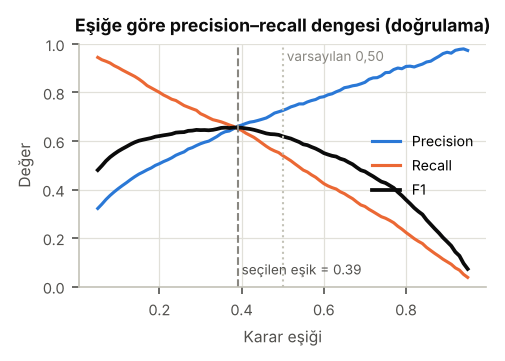

In [25]:
# Grafik 9 — Eşik seçimi: precision / recall / F1 dengesi (doğrulama seti, ana CNN)
p_val = olasilik(cnn, Xn_va, Xc_va)
pr_list = [precision_score(y_val_np, p_val >= t, zero_division=0) for t in ESIKLER]
rc_list = [recall_score(y_val_np, p_val >= t) for t in ESIKLER]
f1_list = [f1_score(y_val_np, p_val >= t, zero_division=0) for t in ESIKLER]
fig, ax = plt.subplots(figsize=(3.5, 2.1))
ax.plot(ESIKLER, pr_list, color=RENK_ODEDI, label="Precision")
ax.plot(ESIKLER, rc_list, color=RENK_TEMERRUT, label="Recall")
ax.plot(ESIKLER, f1_list, color="#0b0b0b", lw=1.8, label="F1")
ax.axvline(ESIK, color="#898781", ls="--", lw=1)
ax.text(ESIK + 0.01, 0.05, f"seçilen eşik = {ESIK:.2f}", color="#52514e", fontsize=6.5)
ax.axvline(0.5, color=RENK_GRI, ls=":", lw=1)
ax.text(0.51, 0.93, "varsayılan 0,50", color="#898781", fontsize=6.5)
ax.set_xlabel("Karar eşiği"); ax.set_ylabel("Değer"); ax.set_ylim(0, 1)
ax.set_title("Eşiğe göre precision–recall dengesi (doğrulama)"); ax.legend(loc="center right")
kaydet(fig, "fig09_esik_secimi")

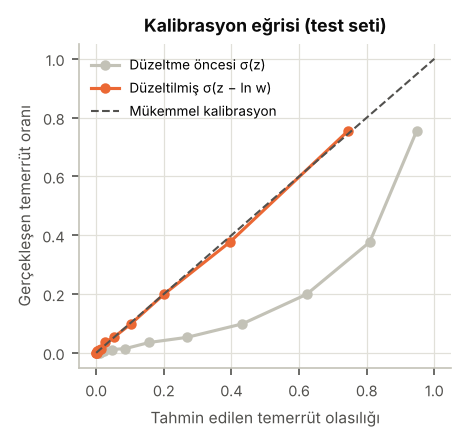

Ortalama tahmin — düzeltme öncesi: %28.4, sonrası: %12.9, gerçek: %12.9


In [26]:
# Grafik 10 — Kalibrasyon: model "%30 risk" dediğinde gerçekten ~%30'u mu temerrüde düşüyor?
p_ham = torch.sigmoid(logit_tahmin(cnn, Xn_te, Xc_te)).numpy()     # düzeltme öncesi
fig, ax = plt.subplots(figsize=(3.2, 2.8))
for p, etiket, renk in [(p_ham, "Düzeltme öncesi σ(z)", RENK_GRI), (p_test, "Düzeltilmiş σ(z − ln w)", RENK_TEMERRUT)]:
    gercek, tahmini = calibration_curve(y_test_np, p, n_bins=12, strategy="quantile")
    ax.plot(tahmini, gercek, marker="o", color=renk, label=etiket)
ax.plot([0, 1], [0, 1], color="#52514e", ls="--", lw=1, label="Mükemmel kalibrasyon")
ax.set_xlabel("Tahmin edilen temerrüt olasılığı"); ax.set_ylabel("Gerçekleşen temerrüt oranı")
ax.set_title("Kalibrasyon eğrisi (test seti)"); ax.legend(fontsize=6.5)
kaydet(fig, "fig10_kalibrasyon")
print(f"Ortalama tahmin — düzeltme öncesi: %{p_ham.mean()*100:.1f}, sonrası: %{p_test.mean()*100:.1f}, gerçek: %{y_test_np.mean()*100:.1f}")

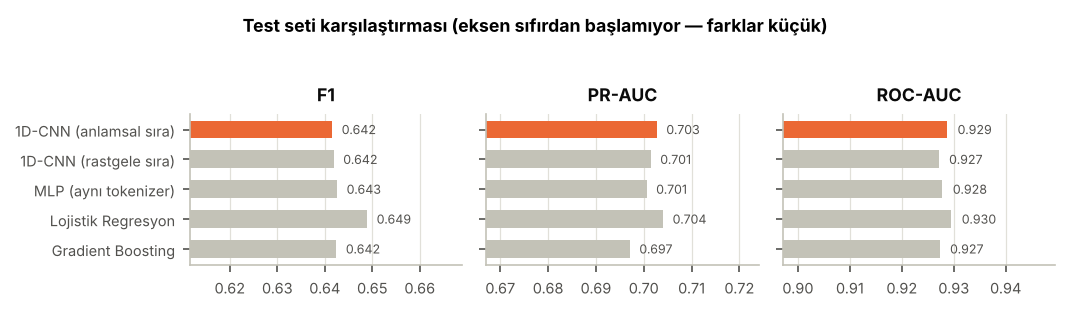

In [27]:
# Grafik 11 — Model karşılaştırması
karsilastir = sonuc_tablo.drop(index="Naif taban (hep 0)")[["F1", "PR-AUC", "ROC-AUC"]]
fig, axes = plt.subplots(1, 3, figsize=(7.16, 1.9), sharey=True)
for ax, metrik in zip(axes, ["F1", "PR-AUC", "ROC-AUC"]):
    degerler = karsilastir[metrik]
    renk = [RENK_TEMERRUT if ad.startswith("1D-CNN (anlamsal") else RENK_GRI for ad in degerler.index]
    ax.barh(degerler.index, degerler.values, color=renk, height=0.6)
    for i, v in enumerate(degerler.values):
        ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=6, color="#52514e")
    lo = degerler.min() - 0.03
    ax.set_xlim(lo, degerler.max() + 0.02); ax.set_title(metrik); ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.suptitle("Test seti karşılaştırması (eksen sıfırdan başlamıyor — farklar küçük)", fontweight="bold", fontsize=8.5, y=1.05)
fig.tight_layout()
kaydet(fig, "fig11_model_karsilastirma")

## 8. Hata Analizi

In [28]:
# Test setini dört gruba ayıralım: TP, TN, FP (yanlış alarm), FN (kaçırılan temerrüt)
analiz = df_test.copy()
analiz["p"] = p_test
analiz["tahmin"] = tahmin_test
analiz["grup"] = np.select(
    [(analiz.Temerrut == 1) & (analiz.tahmin == 1), (analiz.Temerrut == 0) & (analiz.tahmin == 0),
     (analiz.Temerrut == 0) & (analiz.tahmin == 1), (analiz.Temerrut == 1) & (analiz.tahmin == 0)],
    ["TP (yakalanan temerrüt)", "TN (doğru onay)", "FP (yanlış alarm)", "FN (kaçırılan temerrüt)"], default="?")
profil_cols = ["Kredi_Skoru", "Gec_Odeme_Sayisi_12_Ay", "Maksimum_Gecikme_Gunu", "Borc_Gelir_Orani",
               "Son_12_Ay_Odeme_Orani", "Yas", "Aylik_Gelir_TL", "p"]
profil = analiz.groupby("grup")[profil_cols].median()
profil.insert(0, "adet", analiz.grup.value_counts())
profil.round(3)

,adet,Kredi_Skoru,Gec_Odeme_Sayisi_12_Ay,Maksimum_Gecikme_Gunu,Borc_Gelir_Orani,Son_12_Ay_Odeme_Orani,Yas,Aylik_Gelir_TL,p
grup,,,,,,,,,
FN (kaçırılan temerrüt),716,592.5,2.0,7.0,0.575,0.767,35.0,33850.0,0.186
FP (yanlış alarm),645,559.0,2.0,15.0,0.746,0.689,32.0,29900.0,0.532
TN (doğru onay),12421,651.0,1.0,7.0,0.367,0.842,41.0,44100.0,0.010
TP (yakalanan temerrüt),1218,541.5,3.0,15.0,0.780,0.659,29.0,28600.0,0.707


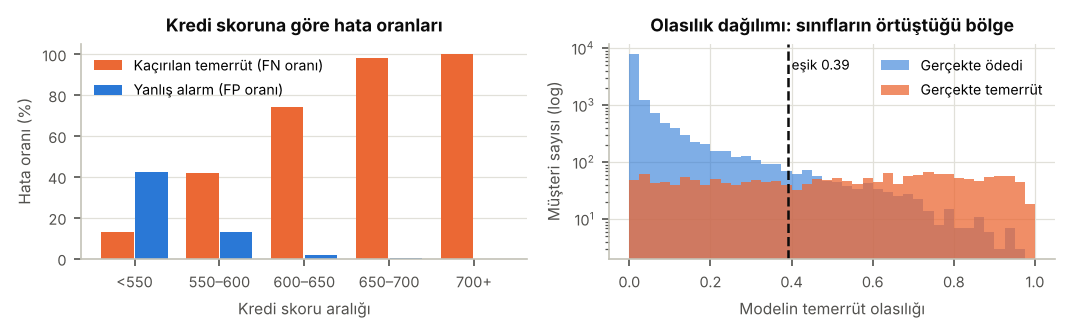

             temerrüt_sayısı  FN_oranı_%  ödeyen_sayısı  FP_oranı_%
Kredi_Skoru                                                        
<550                     808        13.0            648        42.1
550–600                  734        41.8           2285        13.0
600–650                  336        74.1           3837         1.9
650–700                   53        98.1           3430         0.1
700+                       3       100.0           2866         0.0

Skoru ≥ 650 olan 61 temerrüt vakasından yakalanan: 2 (tüm temerrütlerin %3.2'i bu grupta)
Tüm kaçırılan temerrütlerin (FN) %43.6'inin skoru ≥ 600


In [29]:
# Grafik 12 — Hataların kredi skoruna göre dağılımı ve olasılık histogramı
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.16, 2.25))
skor_bin = pd.cut(analiz.Kredi_Skoru, [349, 550, 600, 650, 700, 850], labels=["<550", "550–600", "600–650", "650–700", "700+"])
fn_orani = analiz[analiz.Temerrut == 1].groupby(skor_bin[analiz.Temerrut == 1], observed=True).apply(lambda g: (g.tahmin == 0).mean())
fp_orani = analiz[analiz.Temerrut == 0].groupby(skor_bin[analiz.Temerrut == 0], observed=True).apply(lambda g: (g.tahmin == 1).mean())
x = np.arange(len(fn_orani))
ax1.bar(x - 0.2, fn_orani.values * 100, width=0.38, color=RENK_TEMERRUT, label="Kaçırılan temerrüt (FN oranı)")
ax1.bar(x + 0.2, fp_orani.values * 100, width=0.38, color=RENK_ODEDI, label="Yanlış alarm (FP oranı)")
ax1.set_xticks(x, fn_orani.index); ax1.set_xlabel("Kredi skoru aralığı"); ax1.set_ylabel("Hata oranı (%)")
ax1.set_title("Kredi skoruna göre hata oranları"); ax1.legend(); ax1.grid(axis="x", visible=False)

bins = np.linspace(0, 1, 41)
ax2.hist(analiz.loc[analiz.Temerrut == 0, "p"], bins=bins, color=RENK_ODEDI, alpha=0.6, label="Gerçekte ödedi")
ax2.hist(analiz.loc[analiz.Temerrut == 1, "p"], bins=bins, color=RENK_TEMERRUT, alpha=0.75, label="Gerçekte temerrüt")
ax2.axvline(ESIK, color="#0b0b0b", ls="--", lw=1.2); ax2.text(ESIK + 0.01, ax2.get_ylim()[1] * 0.5, f"eşik {ESIK:.2f}", fontsize=6.5)
ax2.set_yscale("log"); ax2.set_xlabel("Modelin temerrüt olasılığı"); ax2.set_ylabel("Müşteri sayısı (log)")
ax2.set_title("Olasılık dağılımı: sınıfların örtüştüğü bölge"); ax2.legend()
fig.tight_layout()
kaydet(fig, "fig12_hata_analizi")

# Rapor için: her skor aralığında kaç gerçek temerrüt/ödeyen var ve hata oranları
hata_tablo = pd.DataFrame({
    "temerrüt_sayısı": analiz[analiz.Temerrut == 1].groupby(skor_bin[analiz.Temerrut == 1], observed=True).size(),
    "FN_oranı_%": (fn_orani * 100).round(1),
    "ödeyen_sayısı": analiz[analiz.Temerrut == 0].groupby(skor_bin[analiz.Temerrut == 0], observed=True).size(),
    "FP_oranı_%": (fp_orani * 100).round(1)})
print(hata_tablo)
yuksek = analiz[(analiz.Temerrut == 1) & (analiz.Kredi_Skoru >= 650)]
print(f"\nSkoru ≥ 650 olan {len(yuksek)} temerrüt vakasından yakalanan: {(yuksek.tahmin == 1).sum()} "
      f"(tüm temerrütlerin %{len(yuksek) / (analiz.Temerrut == 1).sum() * 100:.1f}'i bu grupta)")
print(f"Tüm kaçırılan temerrütlerin (FN) %{(analiz[analiz.grup.str.startswith('FN')].Kredi_Skoru >= 600).mean() * 100:.1f}'inin skoru ≥ 600")

In [30]:
# Modelin en emin olduğu halde yanıldığı örnekler
gosterim = ["Kredi_Skoru", "Gec_Odeme_Sayisi_12_Ay", "Maksimum_Gecikme_Gunu", "Borc_Gelir_Orani",
            "Son_12_Ay_Odeme_Orani", "Yas", "Aylik_Gelir_TL", "Calisma_Durumu", "p"]
print("En düşük olasılık verilen ama temerrüde düşen 5 müşteri (FN):")
display(analiz[analiz.grup.str.startswith("FN")].nsmallest(5, "p")[gosterim].round(3))
print("En yüksek olasılık verilen ama ödeyen 5 müşteri (FP):")
display(analiz[analiz.grup.str.startswith("FP")].nlargest(5, "p")[gosterim].round(3))

En düşük olasılık verilen ama temerrüde düşen 5 müşteri (FN):


,Kredi_Skoru,Gec_Odeme_Sayisi_12_Ay,Maksimum_Gecikme_Gunu,Borc_Gelir_Orani,Son_12_Ay_Odeme_Orani,Yas,Aylik_Gelir_TL,Calisma_Durumu,p
37049,710,2,1,0.270,0.684,38,42900,Maaşlı,0.001
31546,630,0,1,0.081,0.812,44,46300,Maaşlı,0.003
73053,665,0,0,0.809,0.978,46,38500,Serbest,0.003
7430,628,0,0,0.313,0.781,54,32100,Emekli,0.004
71815,654,0,0,0.070,0.994,28,20600,Maaşlı,0.004


En yüksek olasılık verilen ama ödeyen 5 müşteri (FP):


,Kredi_Skoru,Gec_Odeme_Sayisi_12_Ay,Maksimum_Gecikme_Gunu,Borc_Gelir_Orani,Son_12_Ay_Odeme_Orani,Yas,Aylik_Gelir_TL,Calisma_Durumu,p
45535,470,2,15,1.031,0.879,29,27200,Maaşlı,0.958
20622,488,3,15,0.748,0.562,23,21300,Maaşlı,0.951
84644,465,3,30,0.697,0.808,26,30800,Maaşlı,0.951
41346,497,4,30,0.654,0.571,19,27400,Maaşlı,0.948
97437,509,5,90,0.611,0.459,38,33200,Maaşlı,0.941


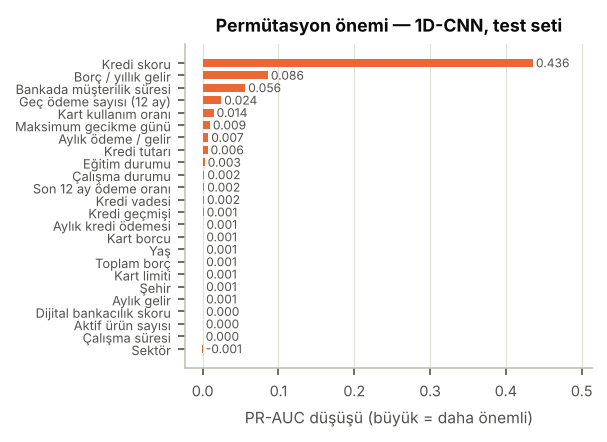

In [31]:
# Grafik 13 — Permütasyon önemi: bir değişkeni test setinde karıştırınca PR-AUC ne kadar düşüyor?
def permutasyon_onemi(model, tekrar=3):
    temel = average_precision_score(y_test_np, olasilik(model, Xn_te, Xc_te))
    rng = np.random.default_rng(SEED); sonuc = {}
    for j, ad in enumerate(TUM_DEGISKENLER):
        dususler = []
        for _ in range(tekrar):
            Xn_p, Xc_p = Xn_te.clone(), Xc_te.clone()
            perm = torch.as_tensor(rng.permutation(len(Xn_te)))
            if j < len(NUM_COLS): Xn_p[:, j] = Xn_p[perm, j]
            else:                 Xc_p[:, j - len(NUM_COLS)] = Xc_p[perm, j - len(NUM_COLS)]
            dususler.append(temel - average_precision_score(y_test_np, olasilik(model, Xn_p, Xc_p)))
        sonuc[ad] = np.mean(dususler)
    return pd.Series(sonuc).sort_values()

onem = permutasyon_onemi(cnn)
fig, ax = plt.subplots(figsize=(3.5, 2.8))
ax.barh([ETIKET[k] for k in onem.index], onem.values, color=RENK_TEMERRUT, height=0.65)
ax.set_xlim(right=onem.max() * 1.18); ax.tick_params(axis="y", labelsize=6.2)
for i, v in enumerate(onem.values):
    ax.text(max(v, 0) + 0.004, i, f"{v:.3f}", va="center", fontsize=5.8, color="#52514e")
ax.set_xlabel("PR-AUC düşüşü (büyük = daha önemli)"); ax.grid(axis="y", visible=False)
ax.set_title("Permütasyon önemi — 1D-CNN, test seti")
kaydet(fig, "fig13_permutasyon_onemi")

## 9. Sonuçların Yorumlanması ve Geliştirme Önerileri

### 9.1 Genel değerlendirme
Test setinde 1D-CNN modeli **Accuracy 0,909 · Precision 0,654 · Recall 0,630 · F1 0,642 · ROC-AUC 0,929 · PR-AUC 0,703** elde etti. Naif taban (herkese "ödüyor" demek) %87,1 accuracy alıyor ama F1 = 0 ve PR-AUC = 0,129. Model PR-AUC'yi **5,4 kat** artırıyor. Pratikte model gerçek temerrütlerin **%63'ünü** yakalıyor ve alarm verdiği her 3 müşteriden yaklaşık 2'si gerçekten temerrüde düşüyor.

### 9.2 Karşılaştırma ve ablasyon: evrişim bu veride ne kattı?
| Model | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|
| 1D-CNN (anlamsal sıra) | 0,642 | 0,929 | 0,703 |
| 1D-CNN (rastgele sıra) | 0,642 | 0,927 | 0,701 |
| MLP (aynı tokenizer) | 0,643 | 0,928 | 0,701 |
| Lojistik Regresyon | 0,649 | 0,930 | 0,704 |
| Gradient Boosting | 0,642 | 0,927 | 0,697 |

- Beş model de **neredeyse aynı tavana** takılıyor; farklar binde birler düzeyinde. Bu kadar küçük farkların anlamlı olup olmadığını söylemek için çok tohumlu tekrar veya çapraz doğrulama gerekir.
- **Anlamsal sıra ile rastgele sıra arasında belirgin fark yok.** MLP de aynı seviyede. Yani evrişimin yerellik varsayımı bu veride ek bir kazanç sağlamadı.
- Nedeni, **lojistik regresyonun da aynı başarıya ulaşması.** Log ve ölçek dönüşümünden sonra değişkenler ile risk arasındaki ilişki büyük ölçüde **doğrusal ve toplamsal**. Evrişimin yakalayabileceği karmaşık değişken etkileşimleri veride bulunmuyor.
- Olasılık histogramında (Grafik 12) iki sınıfın **0,1–0,7 aralığında yoğun biçimde örtüştüğü** görülüyor. Aynı profile sahip müşterilerin bir kısmı ödüyor, bir kısmı ödemiyor. Bu örtüşme verideki değişkenlerle açıklanamayan bir belirsizliktir ve hangi model seçilirse seçilsin aşılamaz.

Bu sonuç bir başarısızlık değil, **dürüst bir bulgu**: Tablo verisinde derin öğrenme, ancak veride doğrusal olmayan zengin etkileşimler varsa klasik modelleri geçer.

### 9.3 Güçlü yönler
- **Yüksek ayırma gücü** (ROC-AUC ≈ 0,93): Rastgele seçilen bir temerrüt vakasına, rastgele seçilen bir ödeyen müşteriden daha yüksek risk verme olasılığı %93.
- **İyi kalibre olasılıklar:** `ln(w)` düzeltmesiyle ortalama tahmin %12,9'a iniyor; gerçek oran da %12,9. Düzeltme öncesi bu değer %28,4'tü. Model "%30 risk" dediğinde, gerçekten de bu müşterilerin yaklaşık %30'u temerrüde düşüyor. Bu, risk fiyatlaması için önemlidir.
- **Hafif ve hızlı:** 30 bin parametre, CPU'da yaklaşık 50 saniyede eğitiliyor. Bu sayede tarayıcıda bile çalışabiliyor (bkz. deneme uygulaması).
- Kategorik değişkenler embedding ile işleniyor. 30 şehir için 30 one-hot sütun açmak yerine 16 boyutlu yoğun bir temsil öğreniliyor.

### 9.4 Zayıf yönler ve hata analizi
1. **Kredi skoruna aşırı bağımlılık.** Permütasyon önemine göre kredi skoru karıştırıldığında PR-AUC **0,436** düşüyor. İkinci sıradaki borç/gelir oranında bu düşüş yalnızca 0,086. Kaçırma oranı skor yükseldikçe hızla artıyor: 550'nin altında %13, 550–600 arasında %42, 600–650 arasında %74. **Skoru 650'nin üzerindeki 56 temerrüt vakasından yalnızca biri yakalanıyor** (Grafik 12, sol). Ancak bu grup küçük (tüm temerrütlerin %2,9'u); kaçırılan 716 vakanın %78'i 550–650 aralığında.
2. **Kaçırılan temerrütler "temiz görünen" müşteriler.** Bu gruptaki müşterilerin medyan kredi skoru 593 (yakalananlarda 542), medyan geç ödeme sayısı 2 ve medyan maksimum gecikme 7 gün. Profilleri ödeyen müşterilere çok benziyor. Temerrütlerinin nedeni büyük olasılıkla veride bulunmayan olaylar (iş kaybı, sağlık sorunu, ani gelir şoku).
3. **Yanlış alarmlar düşük skorlu ama ödeyen müşterilerde yoğunlaşıyor.** Kredi skoru 550'nin altında olup ödeyen müşterilerin yaklaşık %42'si alarm alıyor. Modelin en emin olduğu yanlış alarmlar tüm ölçütlere göre riskli görünüyor: skor 465–510, 2–5 geç ödeme, borç/gelir oranı 0,6–1,0. Banka açısından bu, iyi müşteriyi geri çevirerek gelir kaybetmek anlamına gelir.
4. **Eşik maliyet duyarlı değil.** Eşik (0,39) F1'e göre seçildi. Bu yaklaşım iki hata türünü eşit sayar. Oysa gerçekte kaçırılan bir temerrüdün maliyeti (anaparanın kaybı), yanlış bir alarmın maliyetinden (kaçan faiz geliri) genellikle çok daha yüksektir.
5. **Yorumlanabilirlik.** Model bir kara kutu; kararını açıklamak için permütasyon önemi veya occlusion gibi ek yöntemler gerekiyor. Ayrıca **yaş**, hedefle −0,27 korelasyona sahip olmasına rağmen düşük önem alıyor. Bunun nedeni, yaşın taşıdığı bilginin kredi geçmişi ve müşterilik süresi gibi değişkenlerle örtüşmesi. Birbirine bağlı değişkenler arasında önem bölüşülüyor.
6. **CNN'in tümevarımsal önyargısı** tablo verisine doğal olarak uymuyor. Token sırası elle belirlendi ve ablasyon bu sıranın etkisinin düşük olduğunu gösterdi.

### 9.5 Geliştirme önerileri
- **Maliyet duyarlı eşik:** FN ve FP için TL cinsinden maliyet tanımlanmalı ve beklenen kaybı en aza indiren eşik seçilmeli.
- **Zaman serisi verisi:** Müşterinin aylık ödeme geçmişi (örneğin 24 aylık gecikme dizisi) eklenirse 1D-CNN asıl gücünü gösterebilir. Zaman ekseninde ardışık aylar gerçekten ilişkilidir; yerellik varsayımı orada doğal olarak geçerlidir. **Bu proje için CNN'i haklı çıkaracak en güçlü geliştirme budur.**
- **Tablo verisine özel mimariler:** FT-Transformer (bu projedeki Feature Tokenizer zaten onun giriş katmanıdır) veya TabNet. Dikkat (attention) mekanizması, değişken sırasından bağımsız etkileşim öğrenir.
- **Focal Loss:** Örtüşme bölgesindeki zor örneklere daha fazla ağırlık verir.
- **Topluluk (ensemble):** CNN, lojistik regresyon ve gradient boosting tahminlerinin ortalaması alınabilir.
- **Güvenilir karşılaştırma:** 5 katlı çapraz doğrulama ve çok tohumlu tekrar yapılmalı. Hiperparametre araması (ör. Optuna) ile token boyutu, kanal sayısı, dropout ve öğrenme oranı denenmeli.
- **Adillik denetimi:** Yaş grupları ve şehirler bazında hata oranları karşılaştırılmalı.
- **Bireysel açıklama:** SHAP değerleri ile her karar için gerekçe üretilmeli.

## 10. Modelin Dışa Aktarılması

Eğitilmiş model iki biçimde kaydedilir:
- `tabular_cnn.pt` — PyTorch ağırlıkları ve yapılandırma (Python'da yeniden yüklemek için).
- `app_model.json` — deneme uygulamasının tarayıcıda çalıştıracağı ağırlıklar, ön işleme parametreleri, eşik ve örnek müşteriler. BatchNorm katmanları, çıkarım (inference) için evrişim ağırlıklarına **katlanır (BN folding)**: `W' = W·γ/√(σ²+ε)`, `b' = (b−μ)·γ/√(σ²+ε) + β`. Bu, eval modundaki BatchNorm ile matematiksel olarak birebir aynı sonucu verir.

In [32]:
# 1) PyTorch kaydı
torch.save({"state_dict": cnn.state_dict(), "prep": prep, "token_sirasi": SIRA_INDEKS, "cat_cards": CAT_CARDS,
            "esik": ESIK, "log_pos_weight": LOG_PW}, f"{OUT_DIR}/tabular_cnn.pt")
with open(f"{OUT_DIR}/preprocess.json", "w", encoding="utf-8") as f:
    json.dump(prep, f, ensure_ascii=False, indent=1)

# 2) Uygulama için JSON
def bn_katla(blok):
    conv, bn = blok[0], blok[1]
    olcek = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    W = conv.weight * olcek[:, None, None]
    b = (conv.bias - bn.running_mean) * olcek + bn.bias
    return {"W": W.detach().cpu().numpy().round(6).tolist(), "b": b.detach().cpu().numpy().round(6).tolist()}

cnn.eval()
yuvarla = lambda t: t.detach().cpu().numpy().round(6).tolist()
agirliklar = {
    "num_w": yuvarla(cnn.tokenizer.num_w), "num_b": yuvarla(cnn.tokenizer.num_b),
    "embs": [yuvarla(e.weight) for e in cnn.tokenizer.embs],
    "conv1": bn_katla(cnn.conv1), "conv2": bn_katla(cnn.conv2), "conv3": bn_katla(cnn.conv3),
    "fc1": {"W": yuvarla(cnn.head[0].weight), "b": yuvarla(cnn.head[0].bias)},
    "fc2": {"W": yuvarla(cnn.head[3].weight), "b": yuvarla(cnn.head[3].bias)},
}

# Açıklama için referans müşteri: sayısallarda eğitim medyanı, kategoriklerde en sık değer
referans = {c: float(df_train[c].median()) for c in NUM_COLS}
referans.update({c: df_train[c].mode()[0] for c in CAT_COLS})

# Uygulamada denenecek gerçek test müşterileri (isim/ID olmadan)
ornek = df_test.sample(400, random_state=SEED)
Xn_o, Xc_o = on_isle(ornek, prep)
ornek_p = olasilik(cnn, Xn_o, Xc_o)
ornek_kayit = []
for (_, satir), p in zip(ornek.iterrows(), ornek_p):
    kayit = {c: (satir[c].item() if hasattr(satir[c], "item") else satir[c]) for c in NUM_COLS + CAT_COLS}
    kayit["Temerrut"] = int(satir.Temerrut); kayit["_p"] = round(float(p), 6)
    ornek_kayit.append(kayit)

app_json = {
    "prep": prep, "token_sirasi": SIRA_INDEKS, "log_pos_weight": LOG_PW, "esik": ESIK,
    "agirliklar": agirliklar, "referans": referans, "etiket": ETIKET,
    "aralik": {c: [float(df[c].min()), float(df[c].max())] for c in NUM_COLS},
    "permutasyon_onemi": onem.sort_values(ascending=False).round(5).to_dict(),
    "test_metrikleri": sonuc_tablo.loc["1D-CNN (anlamsal sıra)"].round(4).to_dict(),
    "ornek_musteriler": ornek_kayit,
}
with open(f"{OUT_DIR}/app_model.json", "w", encoding="utf-8") as f:
    json.dump(app_json, f, ensure_ascii=False)
print("Kaydedildi:", os.listdir(OUT_DIR))
print(f"app_model.json boyutu: {os.path.getsize(f'{OUT_DIR}/app_model.json')/1024:.0f} KB")

Kaydedildi: ['preprocess.json', 'tabular_cnn.pt', 'app_model.json']
app_model.json boyutu: 921 KB


In [33]:
# Kontrol: kaydedilen modeli yeniden yükleyip aynı tahmini verdiğini doğrulayalım
yuklu = torch.load(f"{OUT_DIR}/tabular_cnn.pt", weights_only=False)
cnn2 = TabularCNN(len(NUM_COLS), yuklu["cat_cards"], yuklu["token_sirasi"])
cnn2.load_state_dict(yuklu["state_dict"])
fark = np.abs(olasilik(cnn2, Xn_te, Xc_te) - p_test).max()
print(f"Yeniden yüklenen model ile maksimum olasılık farkı: {fark:.2e}")

Yeniden yüklenen model ile maksimum olasılık farkı: 0.00e+00
